# RevoBank Credit Card Sales Performance

**Author:** Johannes Krysosthomus Thedens Dominggu · RevoU Full Stack Data Analytics (FSDA) 2026

Goal: analyze the behavior of existing credit card customers to find opportunities to increase transaction frequency.

Workflow: **Data Cleaning → EDA → Customer Segmentation (K-Means)**

> **Note:** The dataset was provided by RevoU for a class assignment and is not included in this repository. Outputs that showed `card_number` and `cvv` values have been removed, and the dataset links have been replaced with placeholders. Comments and insights inside the notebook are written in Indonesian.


# Data Preparation

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

## Dataset Card

In [ ]:
#import dataset card
# Dataset provided by RevoU for the assignment (not included in this repo)
SHEET_URL = 'https://drive.google.com/file/d/<FILE_ID>/view'
SHEET_URL_REPLACE = 'https://drive.google.com/uc?id=' + SHEET_URL.split('/')[-2]

print(SHEET_URL_REPLACE)

df_card_ori = pd.read_csv (SHEET_URL_REPLACE)
df_card_ori.head()

[Output removed: contains card_number and cvv values from the practice dataset]


## Dataset User

In [ ]:
#import dataset user
# Dataset provided by RevoU for the assignment (not included in this repo)
SHEET_URL = 'https://drive.google.com/file/d/<FILE_ID>/view'
SHEET_URL_REPLACE = 'https://drive.google.com/uc?id=' + SHEET_URL.split('/')[-2]

print(SHEET_URL_REPLACE)

df_user_ori = pd.read_csv (SHEET_URL_REPLACE)
df_user_ori.head()

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score
0,825,66,1972-11-25,Female,Rp45.937.000,Rp93.663.000,Rp38.138.095,787
1,1746,68,1972-12-16,Female,Rp59.451.000,Rp121.212.000,Rp57.186.095,701
2,1718,67,1944-11-04,Female,Rp35.586.000,Rp52.535.000,Rp58.666,698
3,708,63,1963-01-12,Female,Rp255.975.000,Rp392.132.000,Rp60.467.238,722
4,1164,70,1982-09-21,Male,Rp84.407.000,Rp172.099.000,Rp54.946.285,675


# Data Cleaning

## Card

In [ ]:
df_card_dc = df_card_ori.copy() #Buat Copy-an dari dataframe card

In [ ]:
df_card_dc.head()

[Output removed: contains card_number and cvv values from the practice dataset]


In [ ]:
df_card_dc.shape

(5599, 14)

## Card Info

In [ ]:
df_card_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5599 entries, 0 to 5598
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      5599 non-null   int64  
 1   client_id               5599 non-null   int64  
 2   card_brand              5599 non-null   object 
 3   card_number             5599 non-null   int64  
 4   expires                 5599 non-null   object 
 5   cvv                     5599 non-null   int64  
 6   credit_limit            5587 non-null   object 
 7   acct_open_date          5599 non-null   object 
 8   year_pin_last_changed   5599 non-null   int64  
 9   days_since_last_trx     5599 non-null   int64  
 10  count_nonfraud_trx_L6M  3707 non-null   float64
 11  amt_nonfraud_trx_L6M    3707 non-null   object 
 12  count_fraud_trx_L6M     547 non-null    float64
 13  amt_fraud_trx_L6M       547 non-null    object 
dtypes: float64(2), int64(6), object(6)
memor

**Data Type yang harus diganti**
*   ID = String
*   client_id = string
*   Expires = datetime
*   credit_limit = float
*   acct_open_date = datetime
*   count_nonfraud_trx_L6M = int
*   amt_nonfraud_trx_L6M = float
*   count_fraud_trx_L6M = int
*   amt_fraud_trx_L6M = float











In [ ]:
df_card_dc.isnull().sum() #untuk mengecek berapa banyak kolom yang terisi dan tidak

,0
id,0
client_id,0
card_brand,0
card_number,0
expires,0
cvv,0
credit_limit,12
acct_open_date,0
year_pin_last_changed,0
days_since_last_trx,0


**Insight**
1.  credit_limit = 12 null
2.  count_nonfraud_trx_L6M = 1892 null
3.  amt_nonfraud_trx_L6M = 1892 null
4.  count_fraud_trx_L6M = 5052 null
5.  amt_fraud_trx_L6M = 5052 null





## Convert Data Type Card

In [ ]:
#Mengganti type data 'id'
df_card_dc['id'] = df_card_dc['id'].astype(str)

In [ ]:
df_card_dc['id'].dtype

dtype('O')

In [ ]:
#Mengganti tipe data 'client_id'
df_card_dc['client_id'] = df_card_dc['client_id'].astype(str)

In [ ]:
df_card_dc['client_id'].dtype

dtype('O')

In [ ]:
# Reset dan ubah ke tanggal akhir bulan
df_card_dc['expires'] = df_card_ori['expires']
df_card_dc['expires'] = pd.to_datetime(df_card_dc['expires'], format='%m/%Y') + pd.offsets.MonthEnd(0)

In [ ]:
df_card_dc['expires'].dtype #mengganti data type expires menjadi datetime

dtype('<M8[ns]')

In [ ]:
#Membersihkan string "Rp" dan titik "." pada credit_limit
df_card_dc['credit_limit'] = (
    df_card_dc['credit_limit']
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
)

In [ ]:
#mengubah tipe data menjadi float
df_card_dc['credit_limit'] = df_card_dc['credit_limit'].astype(float)

#Mengecek tipe data yang sudah diganti
df_card_dc['credit_limit'].dtype

dtype('float64')

In [ ]:
#Mengganti tipe data acct_open_date
df_card_dc['acct_open_date'] = pd.to_datetime(df_card_dc['acct_open_date'])

/tmp/ipykernel_6619/2595955100.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_card_dc['acct_open_date'] = pd.to_datetime(df_card_dc['acct_open_date'])


In [ ]:
#Mengecek apakah tipe datanya sudah berhasil diganti
df_card_dc['acct_open_date'].dtype

dtype('<M8[ns]')

In [ ]:
#Mengganti tipe data dari count_nonfraud_trx_L6M menjadi Int64
df_card_dc['count_nonfraud_trx_L6M'] = df_card_dc['count_nonfraud_trx_L6M'].astype('Int64')

In [ ]:
#Mengecek tipe data yang sudah diubah
df_card_dc['count_nonfraud_trx_L6M'].dtype

Int64Dtype()

In [ ]:
#Menghapus "Rp" dan "." pada data amt_nonfraud_trx_L6M
df_card_dc['amt_nonfraud_trx_L6M'] = (
    df_card_dc['amt_nonfraud_trx_L6M']
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
)

In [ ]:
#Mengubah tipe data amt_nonfraud_trx_L6M menjadi float
df_card_dc['amt_nonfraud_trx_L6M'] = df_card_dc['amt_nonfraud_trx_L6M'].astype (float)

In [ ]:
#Mengecek tipe data yang sudah diganti
df_card_dc['amt_nonfraud_trx_L6M'].dtype

dtype('float64')

In [ ]:
#Mengganti tipe data count_fraud_trx_L6M menjadi Int64
df_card_dc['count_fraud_trx_L6M'] = df_card_dc['count_fraud_trx_L6M'].astype ('Int64')

In [ ]:
#Mengecek tipe data yang sudah diganti
df_card_dc['count_fraud_trx_L6M'].dtype

Int64Dtype()

In [ ]:
#Menghapus string "Rp" dan "." pada data amt_fraud_trx_L6M
df_card_dc['amt_fraud_trx_L6M'] = (
    df_card_dc['amt_fraud_trx_L6M']
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
)

In [ ]:
#Mengganti tipe data amt_fraud_trx_L6M menjadi float
df_card_dc['amt_fraud_trx_L6M'] = df_card_dc['amt_fraud_trx_L6M'].astype(float)

In [ ]:
#Cek tipe data yang sudah diubah
df_card_dc['amt_fraud_trx_L6M'].dtype

dtype('float64')

## Check Values and Typo

In [ ]:
df_card_dc.columns

Index(['id', 'client_id', 'card_brand', 'card_number', 'expires', 'cvv',
       'credit_limit', 'acct_open_date', 'year_pin_last_changed',
       'days_since_last_trx', 'count_nonfraud_trx_L6M', 'amt_nonfraud_trx_L6M',
       'count_fraud_trx_L6M', 'amt_fraud_trx_L6M'],
      dtype='object')

In [ ]:
df_card_dc[df_card_dc.columns[1]].value_counts()

,count
client_id,
797,9
1301,9
921,9
1345,8
665,8
...,...
579,1
557,1
587,1


In [ ]:
df_card_dc[df_card_dc.columns[2]].value_counts()

,count
card_brand,
Mastercard,2826
Visa,2093
Amex,402
JCB,206
Visa,69
Jcb,3


**Recommendation**
1. Terdapat typo pada Visa dan JCB

In [ ]:
df_card_dc['card_brand'].replace(["Jcb","JCB"],'JCB', inplace = True)
df_card_dc['card_brand'] = df_card_dc['card_brand'].str.strip()

/tmp/ipykernel_6619/656398792.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_card_dc['card_brand'].replace(["Jcb","JCB"],'JCB', inplace = True)


In [ ]:
df_card_dc[df_card_dc.columns[2]].value_counts()

,count
card_brand,
Mastercard,2826
Visa,2162
Amex,402
JCB,209


In [ ]:
df_card_dc[df_card_dc.columns[3]].value_counts()

[Output removed: contains card_number and cvv values from the practice dataset]


In [ ]:
df_card_dc[df_card_dc.columns[4]].value_counts()

,count
expires,
2026-02-28,350
2026-01-31,127
2030-03-31,106
2026-11-30,105
2030-10-31,102
...,...
2024-09-30,1
2025-01-31,1
2024-10-31,1


In [ ]:
df_card_dc[df_card_dc.columns[5]].value_counts()

[Output removed: contains card_number and cvv values from the practice dataset]


In [ ]:
df_card_dc[df_card_dc.columns[6]].value_counts()

,count
credit_limit,
12552000.0,25
0.0,25
13650000.0,25
14592000.0,25
11140000.0,24
...,...
21567000.0,1
27180000.0,1
47324000.0,1


**Recomendation**
1. Nilai null pada credit_limit sebaiknya diganti dengan angka 0 dengan pertimbangan agar bisa dijalankan dengan filter credit_limit > 0

In [ ]:
df_card_dc['credit_limit'] = df_card_dc['credit_limit'].fillna(0)

In [ ]:
df_card_dc[df_card_dc.columns[7]].value_counts()

,count
acct_open_date,
2020-02-01,233
2025-02-01,82
2020-01-01,79
2025-01-01,78
2015-02-01,51
...,...
2002-09-01,1
1998-09-01,1
1997-10-01,1


In [ ]:
df_card_dc[df_card_dc.columns[8]].value_counts()

,count
year_pin_last_changed,
2025,1083
2016,734
2015,657
2017,435
2018,432
2014,404
2019,374
2020,318
2013,278


In [ ]:
df_card_dc[df_card_dc.columns[9]].value_counts()

,count
days_since_last_trx,
604,1884
13,143
27,138
14,138
24,133
...,...
434,1
135,1
106,1


In [ ]:
df_card_dc[df_card_dc.columns[10]].value_counts()

,count
count_nonfraud_trx_L6M,
41,23
74,23
46,22
64,22
94,21
...,...
610,1
908,1
512,1


**Recomendation**
1. Kolom yang null diisi dengan nol, agar kedepannya bisa dianalisis menggunakan agregasi dll

In [ ]:
df_card_dc['count_nonfraud_trx_L6M'] = df_card_dc['count_nonfraud_trx_L6M'].fillna(0)

In [ ]:
df_card_dc[df_card_dc.columns[11]].value_counts()

,count
amt_nonfraud_trx_L6M,
111340900.0,2
30218000.0,2
43768500.0,2
182600200.0,2
15806700.0,2
...,...
106866500.0,1
65903600.0,1
378188300.0,1


**Recomendation**
1. Kolom yang null diisi dengan nol, agar kedepannya bisa dianalisis menggunakan agregasi dll

In [ ]:
df_card_dc['amt_nonfraud_trx_L6M'] = df_card_dc['amt_nonfraud_trx_L6M'].fillna(0)

In [ ]:
df_card_dc[df_card_dc.columns[12]].value_counts()

,count
count_fraud_trx_L6M,
1,449
2,85
3,12
4,1


**Recommendation**
1. Mengisi kolom yang null menjadi nol, agar kedepannya bisa dianalisis menggunakan agregasi dll

In [ ]:
df_card_dc['count_fraud_trx_L6M'] = df_card_dc['count_fraud_trx_L6M'].fillna(0)

In [ ]:
df_card_dc[df_card_dc.columns[13]].value_counts()

,count
amt_fraud_trx_L6M,
564800.0,2
50500.0,2
20700.0,2
588100.0,2
200.0,2
...,...
3877800.0,1
110000.0,1
432300.0,1


**Recomenndation**
1. Kolom yang null diisi 0, agar kedepannya bisa dianalisis menggunakan agregasi dll

In [ ]:
df_card_dc['amt_fraud_trx_L6M'] = df_card_dc['amt_fraud_trx_L6M'].fillna(0)

## Remove Irrelevant Data

Irrelevant data pada dataset card yaitu kolom cvv dan card_number

In [ ]:
#Nama kolom sebelum dihapus
df_card_dc.columns

Index(['id', 'client_id', 'card_brand', 'card_number', 'expires', 'cvv',
       'credit_limit', 'acct_open_date', 'year_pin_last_changed',
       'days_since_last_trx', 'count_nonfraud_trx_L6M', 'amt_nonfraud_trx_L6M',
       'count_fraud_trx_L6M', 'amt_fraud_trx_L6M'],
      dtype='object')

In [ ]:
#Menghapus kolom cvv dan card_number
df_card_dc = df_card_dc.drop(columns=['cvv', 'card_number'])

In [ ]:
#Hasil kolom setelah menghapus cvv dan card_number
df_card_dc.columns

Index(['id', 'client_id', 'card_brand', 'expires', 'credit_limit',
       'acct_open_date', 'year_pin_last_changed', 'days_since_last_trx',
       'count_nonfraud_trx_L6M', 'amt_nonfraud_trx_L6M', 'count_fraud_trx_L6M',
       'amt_fraud_trx_L6M'],
      dtype='object')

## Check Duplicates

In [ ]:
df_card_dc[df_card_dc['id'].duplicated()]

,id,client_id,card_brand,expires,credit_limit,acct_open_date,year_pin_last_changed,days_since_last_trx,count_nonfraud_trx_L6M,amt_nonfraud_trx_L6M,count_fraud_trx_L6M,amt_fraud_trx_L6M
5568,2347,601,Visa,2030-11-30,8473000.0,2020-03-01,2020,29,29,24340700.0,0,0.0
5569,2720,73,Visa,2030-06-30,27068000.0,2018-04-01,2018,7,116,107706500.0,0,0.0
5570,2893,1759,Visa,2030-10-31,17259000.0,2010-05-01,2025,19,154,99452600.0,0,0.0
5571,5353,1561,Visa,2028-07-31,4271000.0,2002-11-01,2021,4,118,82179800.0,0,0.0
5572,4350,1123,Visa,2029-02-28,2187000.0,2015-08-01,2020,4,64,15806700.0,0,0.0
5573,3456,48,Visa,2030-03-31,15845000.0,2014-06-01,2018,8,168,76397900.0,0,0.0
5574,5515,1422,Visa,2031-07-31,10184000.0,2012-11-01,2018,3,99,41753200.0,0,0.0
5575,4867,157,Visa,2027-07-31,21084000.0,2015-01-01,2018,9,31,13155400.0,0,0.0
5576,4972,1308,Visa,2027-07-31,23221000.0,2007-10-01,2017,604,0,0.0,0,0.0
5577,1981,136,Visa,2029-08-31,38605000.0,2023-08-01,2025,604,0,0.0,0,0.0


In [ ]:
#Menghapus id yang teridetifikasi duplikat
df_card_dc = df_card_dc.drop_duplicates(subset=['id'], keep='first')
#Menampilkan total row yang sudah tidak terduplikat, dan berhasil menghapus 31 id duplikat
df_card_dc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5568 entries, 0 to 5567
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      5568 non-null   object        
 1   client_id               5568 non-null   object        
 2   card_brand              5568 non-null   object        
 3   expires                 5568 non-null   datetime64[ns]
 4   credit_limit            5568 non-null   float64       
 5   acct_open_date          5568 non-null   datetime64[ns]
 6   year_pin_last_changed   5568 non-null   int64         
 7   days_since_last_trx     5568 non-null   int64         
 8   count_nonfraud_trx_L6M  5568 non-null   Int64         
 9   amt_nonfraud_trx_L6M    5568 non-null   float64       
 10  count_fraud_trx_L6M     5568 non-null   Int64         
 11  amt_fraud_trx_L6M       5568 non-null   float64       
dtypes: Int64(2), datetime64[ns](2), float64(3), int64(2),

## Data Manipulation

Remove all expired AND 0-valued cards

In [ ]:
#Menentukan tanggal acuan yaitu 31 mei 2025
cutoff_date = pd.to_datetime('2025-05-31')
#Filter kartu aktif dan limit > 0
df_card_dc = df_card_dc[
    (df_card_dc['expires'] >= cutoff_date) &
    (df_card_dc['credit_limit'] > 0)
].copy()
#Menampilkat hasil dari menghapus Expired card and 0-valued Cards
df_card_dc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5531 entries, 0 to 5567
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      5531 non-null   object        
 1   client_id               5531 non-null   object        
 2   card_brand              5531 non-null   object        
 3   expires                 5531 non-null   datetime64[ns]
 4   credit_limit            5531 non-null   float64       
 5   acct_open_date          5531 non-null   datetime64[ns]
 6   year_pin_last_changed   5531 non-null   int64         
 7   days_since_last_trx     5531 non-null   int64         
 8   count_nonfraud_trx_L6M  5531 non-null   Int64         
 9   amt_nonfraud_trx_L6M    5531 non-null   float64       
 10  count_fraud_trx_L6M     5531 non-null   Int64         
 11  amt_fraud_trx_L6M       5531 non-null   float64       
dtypes: Int64(2), datetime64[ns](2), float64(3), int64(2),

## Card Clean Data

In [ ]:
#Membuat copy-an dari dataset card
df_card = df_card_dc.copy()
df_card.head()

,id,client_id,card_brand,expires,credit_limit,acct_open_date,year_pin_last_changed,days_since_last_trx,count_nonfraud_trx_L6M,amt_nonfraud_trx_L6M,count_fraud_trx_L6M,amt_fraud_trx_L6M
0,0,1362,Amex,2030-04-30,53189000.0,1996-01-01,2019,17,181,177057300.0,0,0.0
1,1,550,Mastercard,2030-06-30,18200000.0,1999-01-01,2018,27,148,135687100.0,0,0.0
2,2,556,Mastercard,2027-09-30,31298000.0,2000-01-01,2016,20,415,186723300.0,0,0.0
3,3,1937,Visa,2026-04-30,25732000.0,2000-01-01,2020,7,148,207881500.0,0,0.0
4,4,1981,Mastercard,2030-03-31,30500000.0,2002-01-01,2012,14,48,28007500.0,0,0.0


In [ ]:
#Hasil dari cleaning data pada dataset card
df_card.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5531 entries, 0 to 5567
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      5531 non-null   object        
 1   client_id               5531 non-null   object        
 2   card_brand              5531 non-null   object        
 3   expires                 5531 non-null   datetime64[ns]
 4   credit_limit            5531 non-null   float64       
 5   acct_open_date          5531 non-null   datetime64[ns]
 6   year_pin_last_changed   5531 non-null   int64         
 7   days_since_last_trx     5531 non-null   int64         
 8   count_nonfraud_trx_L6M  5531 non-null   Int64         
 9   amt_nonfraud_trx_L6M    5531 non-null   float64       
 10  count_fraud_trx_L6M     5531 non-null   Int64         
 11  amt_fraud_trx_L6M       5531 non-null   float64       
dtypes: Int64(2), datetime64[ns](2), float64(3), int64(2),

# Data Cleaning

## User

In [ ]:
df_user_dc = df_user_ori.copy() #Buat Copy-an dari dataframe user

In [ ]:
df_user_dc.head()

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score
0,825,66,1972-11-25,Female,Rp45.937.000,Rp93.663.000,Rp38.138.095,787
1,1746,68,1972-12-16,Female,Rp59.451.000,Rp121.212.000,Rp57.186.095,701
2,1718,67,1944-11-04,Female,Rp35.586.000,Rp52.535.000,Rp58.666,698
3,708,63,1963-01-12,Female,Rp255.975.000,Rp392.132.000,Rp60.467.238,722
4,1164,70,1982-09-21,Male,Rp84.407.000,Rp172.099.000,Rp54.946.285,675


In [ ]:
#Menampilkan jumlah baris dan kolom
df_user_dc.shape

(2000, 8)

## User Info

In [ ]:
df_user_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   id                 2000 non-null   int64 
 1   retirement_age     2000 non-null   int64 
 2   birthdate          2000 non-null   object
 3   gender             2000 non-null   object
 4   per_capita_income  2000 non-null   object
 5   yearly_income      2000 non-null   object
 6   total_debt         2000 non-null   object
 7   credit_score       2000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 125.1+ KB


**Tipe data yang harus diganti**
1. id = string
2. birthdate = datetime
3. per_capita_income = float
4. yearly_income = float
5. total_debt = float

In [ ]:
df_user_dc.isnull().sum() #untuk mengecek berapa banyak kolom yang terisi dan tidak

,0
id,0
retirement_age,0
birthdate,0
gender,0
per_capita_income,0
yearly_income,0
total_debt,0
credit_score,0


**Insight**
1. Semua baris tidak ada yang null

## Convert Data Type User

In [ ]:
#Mengganti tipe data 'id'
df_user_dc['id'] = df_user_dc['id'].astype(str)

In [ ]:
#Mengecek tipe data yang sudah diganti
df_user_dc['id'].dtype

dtype('O')

In [ ]:
#Mengganti tipe data 'birthdate'
df_user_dc['birthdate'] = pd.to_datetime(df_user_dc['birthdate'])

In [ ]:
#Mengecek tipe data yang sudah diganti
df_user_dc['birthdate'].dtype

dtype('<M8[ns]')

In [ ]:
#Membersihkan string "Rp" dan titik "." pada 'per_capita_income'
df_user_dc['per_capita_income'] = (
    df_user_dc['per_capita_income']
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
)

In [ ]:
#mengubah tipe data 'per_capita_income menjadi float
df_user_dc['per_capita_income'] = df_user_dc['per_capita_income'].astype(float)

#Mengecek tipe data yang sudah diganti
df_user_dc['per_capita_income'].dtype

dtype('float64')

In [ ]:
#Membersihkan string "Rp" dan titik "." pada 'yearly_income'
df_user_dc['yearly_income'] = (
    df_user_dc['yearly_income']
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
)

In [ ]:
#mengubah tipe data 'yearly_income' menjadi float
df_user_dc['yearly_income'] = df_user_dc['yearly_income'].astype(float)

#Mengecek tipe data yang sudah diganti
df_user_dc['yearly_income'].dtype

dtype('float64')

In [ ]:
#Membersihkan string "Rp" dan titik "." pada 'total_debt'
df_user_dc['total_debt'] = (
    df_user_dc['total_debt']
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
)

In [ ]:
#mengubah tipe data 'total_debt' menjadi float
df_user_dc['total_debt'] = df_user_dc['total_debt'].astype(float)

#Mengecek tipe data yang sudah diganti
df_user_dc['total_debt'].dtype

dtype('float64')

## Check Values and Typo

In [ ]:
df_user_dc.columns

Index(['id', 'retirement_age', 'birthdate', 'gender', 'per_capita_income',
       'yearly_income', 'total_debt', 'credit_score'],
      dtype='object')

In [ ]:
df_user_dc[df_user_dc.columns[1]].value_counts()

,count
retirement_age,
65,314
66,295
67,259
68,195
69,162
70,110
64,109
71,87
62,75


**Insight**
1. Kolom ini akan digunakan untuk menambahkan kolom 'age'

In [ ]:
df_user_dc[df_user_dc.columns[2]].value_counts()

,count
birthdate,
2008-01-14,3
2008-02-09,3
2008-02-18,3
1991-11-03,3
2005-11-14,3
...,...
1999-05-07,1
2002-05-05,1
1974-07-20,1


**Insight**
1. Kolom ini akan digunakan untuk menambahkan kolom baru 'age'

In [ ]:
df_user_dc[df_user_dc.columns[3]].value_counts()

,count
gender,
Female,1016
Male,984


In [ ]:
df_user_dc[df_user_dc.columns[4]].value_counts()

,count
per_capita_income,
0.0,15
30410000.0,4
63331000.0,3
23078000.0,3
24720000.0,3
...,...
25765000.0,1
52190000.0,1
33997000.0,1


In [ ]:
df_user_dc[df_user_dc.columns[5]].value_counts()

,count
yearly_income,
69237000.0,3
51041000.0,2
64550000.0,2
79988000.0,2
52056000.0,2
...,...
106410000.0,1
69320000.0,1
176818000.0,1


**Insight**
1. Kolom ini akan digunakan untuk membuat kolom baru 'DTI'

In [ ]:
df_user_dc[df_user_dc.columns[6]].value_counts()

,count
total_debt,
0.0,102
7145333.0,2
15369714.0,2
12819428.0,2
17257714.0,2
...,...
38899238.0,1
27478666.0,1
61690666.0,1


**Insight**
1. Kolom ini akan digunakan untuk membuat kolom baru 'DTI'

In [ ]:
df_user_dc[df_user_dc.columns[7]].value_counts()

,count
credit_score,
850,34
689,24
685,23
684,22
703,22
...,...
523,1
552,1
517,1


## Check Duplicates

In [ ]:
#Mengecek duplikat data di kolom 'id'
df_user_dc[df_user_dc['id'].duplicated()]

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score


**Insight**
1. Tidak ada id yang terduplikat

In [ ]:
df_user_dc[df_user_dc.duplicated()]

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score


**Insight**
1. Tidak terdapat duplikat pada semua kolom

## Data Manipulation

Menambahkan kolom 'age' , 'retired_flag' , 'DTI'

Kolom 'age'

In [ ]:
#Menentukan tanggal acuan
today_date = pd.Timestamp("2025-05-31")

In [ ]:
#Membuat kolom 'age' per 31 mei 2025
df_user_dc["age"] = today_date.year - df_user_dc["birthdate"].dt.year - (
    (df_user_dc["birthdate"].dt.month > today_date.month) |
    ((df_user_dc["birthdate"].dt.month == today_date.month) & (df_user_dc["birthdate"].dt.day > today_date.day))
).astype(int)

In [ ]:
#Menampilkan kolom 'age'
df_user_dc['age'].value_counts()

,count
age,
17,66
46,49
21,47
19,46
49,45
...,...
97,2
93,2
101,1


Kolom 'retired_flag'

In [ ]:
#Menambahkan kolom 'retired_flag'
df_user_dc["retired_flag"] = np.where(
    df_user_dc["age"] >= df_user_dc["retirement_age"], 1, 0
)

In [ ]:
#Menampilkan kolom 'retired_flag'
df_user_dc['retired_flag'].value_counts()

,count
retired_flag,
0,1715
1,285


Kolom 'DTI'

In [ ]:
#Membuat kolom 'DTI'
df_user_dc["DTI"] = df_user_dc["total_debt"] / df_user_dc["yearly_income"]

In [ ]:
#Menampilkan kolom 'DTI'
df_user_dc['DTI'].value_counts()

,count
DTI,
0.000000,102
0.304600,1
0.257566,1
0.420249,1
0.005545,1
...,...
0.373390,1
0.240408,1
0.374987,1


In [ ]:
df_user_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 2000 non-null   object        
 1   retirement_age     2000 non-null   int64         
 2   birthdate          2000 non-null   datetime64[ns]
 3   gender             2000 non-null   object        
 4   per_capita_income  2000 non-null   float64       
 5   yearly_income      2000 non-null   float64       
 6   total_debt         2000 non-null   float64       
 7   credit_score       2000 non-null   int64         
 8   age                2000 non-null   int64         
 9   retired_flag       2000 non-null   int64         
 10  DTI                2000 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(4), object(2)
memory usage: 172.0+ KB


In [ ]:
df_user_dc.head()

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score,age,retired_flag,DTI
0,825,66,1972-11-25,Female,45937000.0,93663000.0,38138095.0,787,52,0,0.407184
1,1746,68,1972-12-16,Female,59451000.0,121212000.0,57186095.0,701,52,0,0.471786
2,1718,67,1944-11-04,Female,35586000.0,52535000.0,58666.0,698,80,1,0.001117
3,708,63,1963-01-12,Female,255975000.0,392132000.0,60467238.0,722,62,0,0.154201
4,1164,70,1982-09-21,Male,84407000.0,172099000.0,54946285.0,675,42,0,0.319271


In [ ]:
df_user_dc.isnull().sum()

,0
id,0
retirement_age,0
birthdate,0
gender,0
per_capita_income,0
yearly_income,0
total_debt,0
credit_score,0
age,0
retired_flag,0


## User Clean Data

In [ ]:
#Membuat copy-an dari dataset user
df_user = df_user_dc.copy()
df_user.head()

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score,age,retired_flag,DTI
0,825,66,1972-11-25,Female,45937000.0,93663000.0,38138095.0,787,52,0,0.407184
1,1746,68,1972-12-16,Female,59451000.0,121212000.0,57186095.0,701,52,0,0.471786
2,1718,67,1944-11-04,Female,35586000.0,52535000.0,58666.0,698,80,1,0.001117
3,708,63,1963-01-12,Female,255975000.0,392132000.0,60467238.0,722,62,0,0.154201
4,1164,70,1982-09-21,Male,84407000.0,172099000.0,54946285.0,675,42,0,0.319271


In [ ]:
#Hasil dari cleaning data pada dataset user
df_user.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 2000 non-null   object        
 1   retirement_age     2000 non-null   int64         
 2   birthdate          2000 non-null   datetime64[ns]
 3   gender             2000 non-null   object        
 4   per_capita_income  2000 non-null   float64       
 5   yearly_income      2000 non-null   float64       
 6   total_debt         2000 non-null   float64       
 7   credit_score       2000 non-null   int64         
 8   age                2000 non-null   int64         
 9   retired_flag       2000 non-null   int64         
 10  DTI                2000 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(4), object(2)
memory usage: 172.0+ KB


# EDA

## Data Preparation Card

In [ ]:
#Pembuatan data card yang akan digunakan untuk EDA
df_card_eda=df_card.copy()
#Menampilkan 5 baris pertama untuk data EDA
df_card_eda.head()

,id,client_id,card_brand,expires,credit_limit,acct_open_date,year_pin_last_changed,days_since_last_trx,count_nonfraud_trx_L6M,amt_nonfraud_trx_L6M,count_fraud_trx_L6M,amt_fraud_trx_L6M
0,0,1362,Amex,2030-04-30,53189000.0,1996-01-01,2019,17,181,177057300.0,0,0.0
1,1,550,Mastercard,2030-06-30,18200000.0,1999-01-01,2018,27,148,135687100.0,0,0.0
2,2,556,Mastercard,2027-09-30,31298000.0,2000-01-01,2016,20,415,186723300.0,0,0.0
3,3,1937,Visa,2026-04-30,25732000.0,2000-01-01,2020,7,148,207881500.0,0,0.0
4,4,1981,Mastercard,2030-03-31,30500000.0,2002-01-01,2012,14,48,28007500.0,0,0.0


In [ ]:
df_card_eda.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5531 entries, 0 to 5567
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      5531 non-null   object        
 1   client_id               5531 non-null   object        
 2   card_brand              5531 non-null   object        
 3   expires                 5531 non-null   datetime64[ns]
 4   credit_limit            5531 non-null   float64       
 5   acct_open_date          5531 non-null   datetime64[ns]
 6   year_pin_last_changed   5531 non-null   int64         
 7   days_since_last_trx     5531 non-null   int64         
 8   count_nonfraud_trx_L6M  5531 non-null   Int64         
 9   amt_nonfraud_trx_L6M    5531 non-null   float64       
 10  count_fraud_trx_L6M     5531 non-null   Int64         
 11  amt_fraud_trx_L6M       5531 non-null   float64       
dtypes: Int64(2), datetime64[ns](2), float64(3), int64(2),

## Data Preparation User

In [ ]:
df_user_eda = df_user.copy()
df_user_eda.head()

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score,age,retired_flag,DTI
0,825,66,1972-11-25,Female,45937000.0,93663000.0,38138095.0,787,52,0,0.407184
1,1746,68,1972-12-16,Female,59451000.0,121212000.0,57186095.0,701,52,0,0.471786
2,1718,67,1944-11-04,Female,35586000.0,52535000.0,58666.0,698,80,1,0.001117
3,708,63,1963-01-12,Female,255975000.0,392132000.0,60467238.0,722,62,0,0.154201
4,1164,70,1982-09-21,Male,84407000.0,172099000.0,54946285.0,675,42,0,0.319271


In [ ]:
df_user_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 2000 non-null   object        
 1   retirement_age     2000 non-null   int64         
 2   birthdate          2000 non-null   datetime64[ns]
 3   gender             2000 non-null   object        
 4   per_capita_income  2000 non-null   float64       
 5   yearly_income      2000 non-null   float64       
 6   total_debt         2000 non-null   float64       
 7   credit_score       2000 non-null   int64         
 8   age                2000 non-null   int64         
 9   retired_flag       2000 non-null   int64         
 10  DTI                2000 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(4), object(2)
memory usage: 172.0+ KB


## NET PROFIT

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
#MDR fee 1,5%
mdr_rate = 0.015

In [ ]:
#Total volume penjualan non-fraud dan total fraud amount
total_sales_amount = df_card_eda["amt_nonfraud_trx_L6M"].sum()
total_fraud_amount = df_card_eda["amt_fraud_trx_L6M"].sum()

In [ ]:
# Perhitungan MDR fee profit dan Net Profit
mdr_fee_profit = total_sales_amount * mdr_rate
net_profit = mdr_fee_profit

In [ ]:
print("=== NET PROFIT ANALYSIS ===")
print(f"Total Sales Amount (Non-Fraud): Rp {total_sales_amount:,.2f}")
print(f"Total Fraud Amount: Rp {total_fraud_amount:,.2f}")
print(f"MDR Fee Profit (1.5%): Rp {mdr_fee_profit:,.2f}")
print(f"Total Net Profit: Rp {net_profit:,.2f}\n")

=== NET PROFIT ANALYSIS ===
Total Sales Amount (Non-Fraud): Rp 456,056,498,600.00
Total Fraud Amount: Rp 1,013,378,300.00
MDR Fee Profit (1.5%): Rp 6,840,847,479.00
Total Net Profit: Rp 6,840,847,479.00



Insight:
* Performa Keuntungan Bersih (Net Profit): RevoBank membukukan Net Profit murni sebesar Rp 6,84 Miliar dalam 6 bulan terakhir yang bersumber dari pendapatan komisi MDR (1.5%) atas transaksi non-fraud.
* Skala Volume Transaksi Valid: Total volume transaksi non-fraud yang tercatat mencapai Rp 456 Miliar. Hal ini menunjukkan basis transaksi nasabah RevoBank sangat aktif dan sehat, di mana skema komisi MDR 1.5% menjadi sumber pendapatan (top-line revenue) yang sangat efektif.

Recommendation:
1. Optimalisasi Penyesuaian Tarif MDR: Mengingat tingginya volume transaksi non-fraud (Rp 456 Miliar), penyesuaian/peningkatan bertahap tarif MDR sebesar 0,1%–0,2% pada segmen merchant tertentu berpotensi meningkatkan Net Profit secara signifikan tanpa mengganggu volume transaksi nasabah.

## FRAUD RATE

In [ ]:
# Total transaksi gabungan
total_transaction_val = total_sales_amount + total_fraud_amount
fraud_rate = (total_fraud_amount / total_transaction_val) * 100

In [ ]:
print("=== FRAUD RATE ANALYSIS ===")
print(f"Fraud Rate: {fraud_rate:.2f}%\n")

=== FRAUD RATE ANALYSIS ===
Fraud Rate: 0.22%



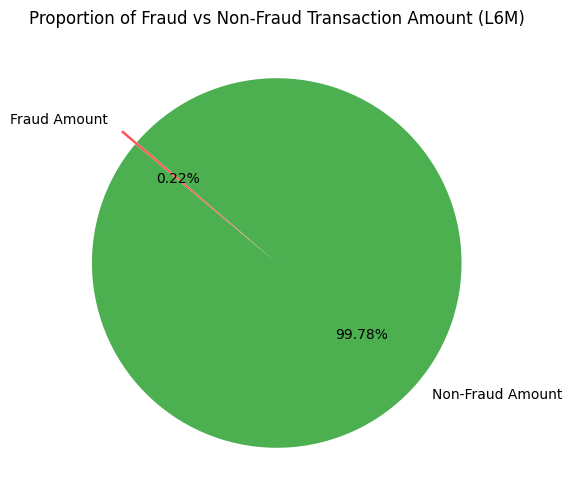

In [ ]:
# Visualisasi Pie Chart
plt.figure(figsize=(6, 6))
labels = ["Non-Fraud Amount", "Fraud Amount"]
amounts = [total_sales_amount, total_fraud_amount]
colors = ["#4CAF50", "#FF5252"]

plt.pie(
    amounts,
    labels=labels,
    autopct="%1.2f%%",
    startangle=140,
    colors=colors,
    explode=(0, 0.1),
)
plt.title("Proportion of Fraud vs Non-Fraud Transaction Amount (L6M)")
plt.show()


Insight:
* Rasio kerugian fraud RevoBank (0,22%) berada jauh di bawah rasio non-fraud (99,78%)
* Hampir seluruh volume transaksi didominasi oleh transaksi non-fraud

Recommendation:
1. Tingkatkan kecerdasan rule-based engine & Machine Learning untuk mendeteksi pola transaksi mencurigakan secara real-time guna menekan nilai kerugian absolut (Rp 1,01 Miliar) hingga > 50%.
2. Wajibkan otentikasi ketat (OTP/Biometrik) pada transaksi high-value atau batas nominal tertentu untuk mencegah risiko carding dan transaksi ilegal.

## Transaction Behaviour per Card Brand

In [ ]:
print("=== TRANSACTION BEHAVIOUR PER CARD BRAND ===")
card_brand_summary = (
    df_card_eda.groupby("card_brand")
    .agg(
        avg_trx_count_nonfraud=("count_nonfraud_trx_L6M", "mean"),
        avg_trx_amt_nonfraud=("amt_nonfraud_trx_L6M", "mean"),
        avg_trx_count_fraud=("count_fraud_trx_L6M", "mean"),
        avg_trx_amt_fraud=("amt_fraud_trx_L6M", "mean"),
    )
    .reset_index()
)

print(card_brand_summary)

=== TRANSACTION BEHAVIOUR PER CARD BRAND ===
   card_brand  avg_trx_count_nonfraud  avg_trx_amt_nonfraud  \
0        Amex              112.822785          9.883078e+07   
1         JCB               84.395122          7.502612e+07   
2  Mastercard              121.933523          8.059584e+07   
3        Visa              116.031634          8.258824e+07   

   avg_trx_count_fraud  avg_trx_amt_fraud  
0             0.126582      206937.721519  
1             0.136585      185500.000000  
2             0.118379      191013.579808  
3             0.117092      168219.641171  


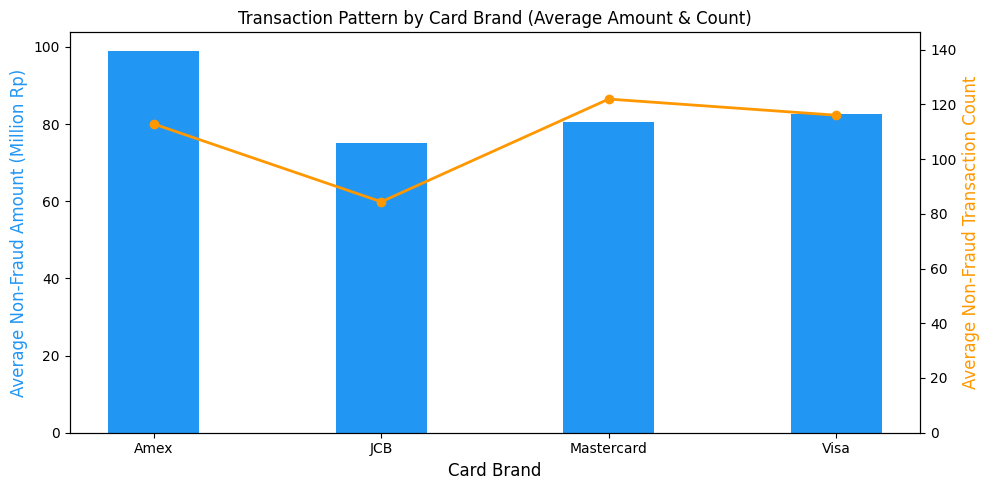

In [ ]:
# Visualisasi Bar Chart untuk Average Transaction Amount per Card Brand
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Rata-rata Nominal Transaksi
ax1.bar(
    card_brand_summary["card_brand"],
    card_brand_summary["avg_trx_amt_nonfraud"] / 1e6,
    color="#2196F3",
    width=0.4,
    label="Avg Non-Fraud Amount (in Millions)",
)
ax1.set_ylabel(
    "Average Non-Fraud Amount (Million Rp)", color="#2196F3", fontsize=12
)
ax1.set_xlabel("Card Brand", fontsize=12)

# Subplot Sumbu Y Kedua untuk Rata-rata Jumlah Transaksi (Count)
ax2 = ax1.twinx()
ax2.plot(
    card_brand_summary["card_brand"],
    card_brand_summary["avg_trx_count_nonfraud"],
    color="#FF9800",
    marker="o",
    linewidth=2,
    label="Avg Non-Fraud Count",
)
ax2.set_ylabel(
    "Average Non-Fraud Transaction Count", color="#FF9800", fontsize=12
)
ax2.set_ylim(
    0, max(card_brand_summary["avg_trx_count_nonfraud"]) * 1.2
)
plt.title("Transaction Pattern by Card Brand (Average Amount & Count)")
fig.tight_layout()
plt.show()

Insight:
* **Amex**: Memiliki rata-rata nominal transaksi tertinggi per nasabah (hampir Rp 100 Juta), dengan intensitas penggunaan yang cukup tinggi (~112 kali). Menunjukkan segmen nasabah high-net-worth / premium spending.
* **Mastercard & Visa**: Menjadi penggerak utama volume transaksi (frekuensi transaksi terbanyak ~100+ kali). Memiliki kombinasi ideal antara rata-rata nominal tinggi (Rp 80M-82M) dan frekuensi paling aktif.
* **JCB**: Memiliki tingkat aktivitas terendah, baik dari segi frekuensi transaksi (~85 kali) maupun rata-rata nominal transaksi per nasabah.

Recommendation:
1. Buat program loyalty/reward berbasis spending threshold untuk menjaga volume transaksi bernilai tinggi dari pemegang kartu Amex.
2. Lakukan evaluasi kemitraan dan kampanye promo khusus (cashback/discount merchant) untuk mendorong frekuensi transaksi penggunanya.

## DTI RATIOS

In [ ]:
import seaborn as sns

In [ ]:
#Menghitung umur per 31 Mei 2025
today_date = pd.to_datetime('2025-05-31')
df_user_eda['age'] = (today_date - df_user_eda['birthdate']).dt.days // 365.25

In [ ]:
#Menentukan retired_flag
df_user_eda['retired_flag'] = np.where(
    df_user_eda['age'] >= df_user_eda['retirement_age'],
    'Retired',
    'Non-Retired'
)

In [ ]:
#Menghitung Debt-to-Income (DTI) Ratio (total_debt / yearly_income)
df_user_eda['dti_ratio'] = df_user_eda['total_debt'] / df_user_eda['yearly_income']

In [ ]:
#Ringkasan statistik agregat
dti_stats = df_user_eda.groupby('retired_flag')['dti_ratio'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).reset_index()
print("--- Ringkasan Statistik DTI ---")
print(dti_stats)

--- Ringkasan Statistik DTI ---
  retired_flag  count      mean    median       std  min       max
0  Non-Retired   1715  0.295747  0.297170  0.153898  0.0  0.948320
1      Retired    285  0.067158  0.044024  0.070973  0.0  0.424106


/tmp/ipykernel_6619/2697550355.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_user_eda, x='retired_flag', y='dti_ratio', palette='Set2')


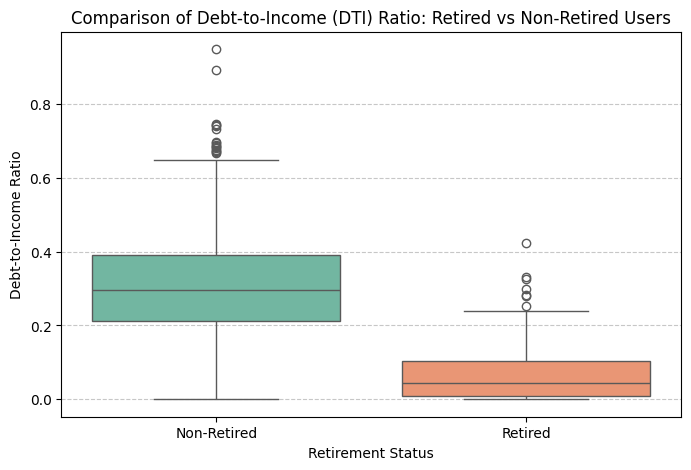

In [ ]:
#Menampilkan Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_user_eda, x='retired_flag', y='dti_ratio', palette='Set2')
plt.title('Comparison of Debt-to-Income (DTI) Ratio: Retired vs Non-Retired Users', fontsize=12)
plt.xlabel('Retirement Status', fontsize=10)
plt.ylabel('Debt-to-Income Ratio', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Insight:
* Distribusi dan Media DTI Ratio:
  * Non-Retired: Memilki tingkat DTI ratio yang signifikan lebih tinggi. Nilai median (garis di tengah box) berada di sekitar 0,29 dengan rentang antarkuartil (IQR) menyebar dari sekitar 0,20 hingga 0,40.
  * Retired: Memiliki DTI ratio yang jauh lebih rendah secara umum. Nilai median berada mendekati angka 0,04 dengan rentang mayoritas data terkonsentrasi di bawah 0,20.
* Outlier:
  * Kelompok Non-Retired memiliki beberapa outlier yang sangat tinggi hingga mencapai DTI ratio diatas 0,80.
  * Kelompok Retired memiliki beberapa outlier, namun nilainya relatif rendah (berada di kisaran antara 0,20 dan 0,60).

## MERGED DATA

In [ ]:
#Agregasi df_card_eda berdasarkan client_id
df_card_agg = df_card_eda.groupby('client_id').agg({
    'days_since_last_trx': 'min', # Recency: mengambil nilai terkecil (paling baru)

    # Monetary & Count: menjumlahkan totalnya (sum)
    'credit_limit': 'sum',
    'count_nonfraud_trx_L6M': 'sum',
    'amt_nonfraud_trx_L6M': 'sum',
    'count_fraud_trx_L6M': 'sum',
    'amt_fraud_trx_L6M': 'sum'
}).reset_index()

In [ ]:
#Merge df_card_agg dengan df_user_eda
df_merged = pd.merge(
    df_user_eda,
    df_card_agg,
    left_on='id',
    right_on='client_id',
    how='inner'
)

In [ ]:
#Hapus kolom non-penting/duplikat (misal client_id hasil gabungan)
df_merged = df_merged.drop(columns=['client_id'])

In [ ]:
df_merged.head()

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score,age,retired_flag,DTI,dti_ratio,days_since_last_trx,credit_limit,count_nonfraud_trx_L6M,amt_nonfraud_trx_L6M,count_fraud_trx_L6M,amt_fraud_trx_L6M
0,825,66,1972-11-25,Female,45937000.0,93663000.0,38138095.0,787,52.0,Non-Retired,0.407184,0.407184,10,164867000.0,599,755489800.0,1,-7421400.0
1,1746,68,1972-12-16,Female,59451000.0,121212000.0,57186095.0,701,52.0,Non-Retired,0.471786,0.471786,24,102033000.0,189,388726600.0,0,0.0
2,1718,67,1944-11-04,Female,35586000.0,52535000.0,58666.0,698,80.0,Retired,0.001117,0.001117,4,209210000.0,1322,705750600.0,0,0.0
3,708,63,1963-01-12,Female,255975000.0,392132000.0,60467238.0,722,62.0,Non-Retired,0.154201,0.154201,4,558975000.0,378,897483900.0,0,0.0
4,1164,70,1982-09-21,Male,84407000.0,172099000.0,54946285.0,675,42.0,Non-Retired,0.319271,0.319271,21,54758000.0,496,763527700.0,0,0.0


In [ ]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1938 entries, 0 to 1937
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      1938 non-null   object        
 1   retirement_age          1938 non-null   int64         
 2   birthdate               1938 non-null   datetime64[ns]
 3   gender                  1938 non-null   object        
 4   per_capita_income       1938 non-null   float64       
 5   yearly_income           1938 non-null   float64       
 6   total_debt              1938 non-null   float64       
 7   credit_score            1938 non-null   int64         
 8   age                     1938 non-null   float64       
 9   retired_flag            1938 non-null   object        
 10  DTI                     1938 non-null   float64       
 11  dti_ratio               1938 non-null   float64       
 12  days_since_last_trx     1938 non-null   int64   

## DTI RATIOS BASED CREDIT SCORE

In [ ]:
# Menentukan rentang batas (bins) dan label kategori
bins = [300, 579, 669, 739, 799, 850]
labels = ['Poor', 'Fair', 'Good', 'Very Good', 'Exceptional']

# Buat kolom baru credit_score_category
df_merged['credit_score_category'] = pd.cut(
    df_merged['credit_score'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [ ]:
# Hitung total transaksi per user jika belum dihitung sebelumnya
df_merged['total_trx_count'] = df_merged['count_nonfraud_trx_L6M'] + df_merged['count_fraud_trx_L6M']
df_merged['total_trx_amt'] = df_merged['amt_nonfraud_trx_L6M'] + df_merged['amt_fraud_trx_L6M']

# Agregasi data berdasarkan kategori credit score
score_summary = df_merged.groupby('credit_score_category', observed=False).agg(
    avg_dti=('dti_ratio', 'mean'),
    avg_trx_count=('total_trx_count', 'mean'),
    avg_trx_amt=('total_trx_amt', 'mean'),
    user_count=('id', 'count')
).reset_index()

print(score_summary)

  credit_score_category   avg_dti  avg_trx_count   avg_trx_amt  user_count
0                  Poor  0.301839     305.753247  2.293360e+08          77
1                  Fair  0.318218     288.214724  2.027734e+08         326
2                  Good  0.250306     337.554217  2.425731e+08         913
3             Very Good  0.245725     366.934783  2.483593e+08         460
4           Exceptional  0.242909     350.623457  2.320513e+08         162


/tmp/ipykernel_6619/2340215450.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_6619/2340215450.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


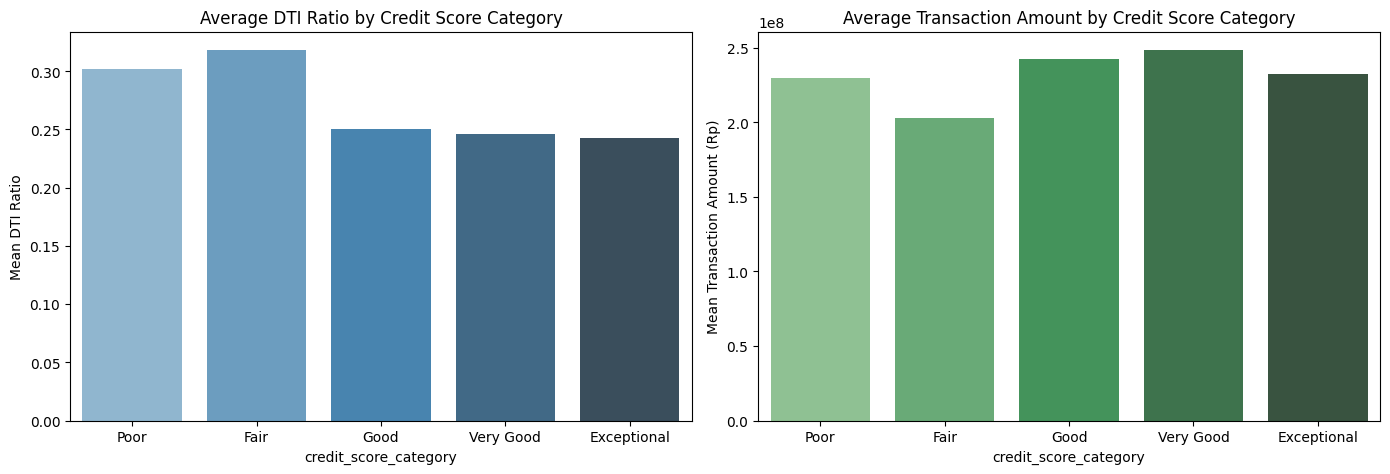

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Average DTI vs Credit Score Category
sns.barplot(
    data=score_summary,
    x='credit_score_category',
    y='avg_dti',
    ax=axes[0],
    palette='Blues_d'
)
axes[0].set_title('Average DTI Ratio by Credit Score Category')
axes[0].set_ylabel('Mean DTI Ratio')

# Plot 2: Average Transaction Amount vs Credit Score Category
sns.barplot(
    data=score_summary,
    x='credit_score_category',
    y='avg_trx_amt',
    ax=axes[1],
    palette='Greens_d'
)
axes[1].set_title('Average Transaction Amount by Credit Score Category')
axes[1].set_ylabel('Mean Transaction Amount (Rp)')

plt.tight_layout()
plt.show()

Insight:
1. Rata-rata DTI Ratio berada pada rentang 0,24 hingga 0,32 (24%–32%). Kelompok Fair mencatatkan DTI tertinggi sebesar 31,8%, diikuti oleh kelompok Poor sebesar 30,2%. Sementara itu, tiga kelompok dengan credit score lebih baik (Good, Very Good, dan Exceptional) menunjukkan tingkat DTI yang lebih rendah dan relatif stabil di kisaran 24%–25%.
2. Rata-rata nominal transaksi per nasabah di seluruh kelompok credit score berada di rentang Rp 200 Juta hingga Rp 248 Juta per 6 bulan. Transaksi tertinggi justru dicatatkan oleh kelompok Very Good (Rp 248 Juta) dan Good (Rp 242 Juta), disusul oleh kelompok Exceptional (Rp 232 Juta) dan Poor (Rp 229,5 Juta). Sementara itu, kelompok Fair mencatatkan rata-rata nominal transaksi paling rendah, yaitu sebesar Rp 202Juta.

RECOMMENDATION:
* Terapkan pembatasan batas kredit (credit limit capping) serta evaluasi ulang rasio DTI secara berkala bagi nasabah kategori Fair dan Poor.
* Insentif Nasabah Sehat: Berikan program promosi atau cashback kepada nasabah kategori Good hingga Exceptional untuk mendorong nilai transaksi mereka tanpa meningkatkan risiko kredit.

## RELATIONSHIP BETWEEN USER AGE AND CREDIT LIMIT

In [ ]:
# Memastikan kolom age dihitung per 31 Mei 2025
df_merged['birthdate'] = pd.to_datetime(df_merged['birthdate'])
today_date = pd.to_datetime('2025-05-31')
df_merged['age'] = (today_date - df_merged['birthdate']).dt.days // 365.25

In [ ]:
#Agregasi: Total limit kredit dibagi jumlah pengguna per kelompok umur (Rata-rata limit)
age_limit_df = df_merged.groupby('age').agg(
    total_credit_limit=('credit_limit', 'sum'),
    user_count=('id', 'count'),
    avg_credit_limit=('credit_limit', 'mean')
).reset_index()

In [ ]:
#Trim rentang umur (misal: 20 hingga 70 tahun) untuk menghindari data yang terlalu sedikit/volatil
age_limit_trimmed = age_limit_df[(age_limit_df['age'] >= 20) & (age_limit_df['age'] <= 70)]

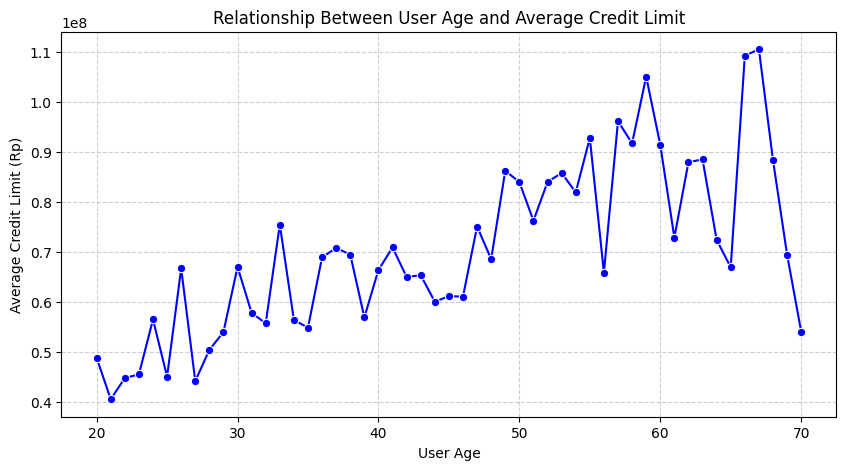

In [ ]:
#Membuat Line Chart
plt.figure(figsize=(10, 5))
sns.lineplot(data=age_limit_trimmed, x='age', y='avg_credit_limit', marker='o', color='b')

plt.title('Relationship Between User Age and Average Credit Limit', fontsize=12)
plt.xlabel('User Age', fontsize=10)
plt.ylabel('Average Credit Limit (Rp)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

1. Hubungan umur dan credit limit
  * Meningkat saat usia produktif (20–50 tahun): Umumnya limit kredit naik seiring bertambahnya usia karena karir dan pendapatan pengguna cenderung meningkat.
  * Puncak & Menurun (Usia senja/pensiun >60 tahun): Limit biasanya mengalami penurunan atau mendatar (stagnant) seiring penurunan kapasitas pendapatan aktif.
2. Rekomendasi meningkatkan penggunaan credit card:
  * Segmentasi Usia Produktif (25–45 tahun): Berikan kenaikan limit secara berkala (credit limit increase program) kepada pengguna di rentang usia ini yang memiliki histori pembayaran baik, karena mereka paling aktif bertransaksi.
  * Program Retensi Usia Senior/Pensiun: Tawarkan benefit khusus yang disesuaikan dengan kebutuhan mereka (seperti diskon kesehatan, minimarket, atau fasilitas perjalanan) agar penggunaan kartu tetap aktif meskipun limit tidak dinaikkan.

# Customer Segmentation

## DATA PREPARATION

In [ ]:
#Membuat copy dari df_merged
df_segmentation=df_merged.copy()

In [ ]:
df_segmentation.head()

,id,retirement_age,birthdate,gender,per_capita_income,yearly_income,total_debt,credit_score,age,retired_flag,...,dti_ratio,days_since_last_trx,credit_limit,count_nonfraud_trx_L6M,amt_nonfraud_trx_L6M,count_fraud_trx_L6M,amt_fraud_trx_L6M,credit_score_category,total_trx_count,total_trx_amt
0,825,66,1972-11-25,Female,45937000.0,93663000.0,38138095.0,787,52.0,Non-Retired,...,0.407184,10,164867000.0,599,755489800.0,1,-7421400.0,Very Good,600,748068400.0
1,1746,68,1972-12-16,Female,59451000.0,121212000.0,57186095.0,701,52.0,Non-Retired,...,0.471786,24,102033000.0,189,388726600.0,0,0.0,Good,189,388726600.0
2,1718,67,1944-11-04,Female,35586000.0,52535000.0,58666.0,698,80.0,Retired,...,0.001117,4,209210000.0,1322,705750600.0,0,0.0,Good,1322,705750600.0
3,708,63,1963-01-12,Female,255975000.0,392132000.0,60467238.0,722,62.0,Non-Retired,...,0.154201,4,558975000.0,378,897483900.0,0,0.0,Good,378,897483900.0
4,1164,70,1982-09-21,Male,84407000.0,172099000.0,54946285.0,675,42.0,Non-Retired,...,0.319271,21,54758000.0,496,763527700.0,0,0.0,Good,496,763527700.0


In [ ]:
df_segmentation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1938 entries, 0 to 1937
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      1938 non-null   object        
 1   retirement_age          1938 non-null   int64         
 2   birthdate               1938 non-null   datetime64[ns]
 3   gender                  1938 non-null   object        
 4   per_capita_income       1938 non-null   float64       
 5   yearly_income           1938 non-null   float64       
 6   total_debt              1938 non-null   float64       
 7   credit_score            1938 non-null   int64         
 8   age                     1938 non-null   float64       
 9   retired_flag            1938 non-null   object        
 10  DTI                     1938 non-null   float64       
 11  dti_ratio               1938 non-null   float64       
 12  days_since_last_trx     1938 non-null   int64   

## Libraries

In [ ]:
# CLUSTER
from sklearn.cluster import KMeans                                             # to perform the k-means algorithm
from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,MaxAbsScaler     # to sacalling different attribute
from sklearn import cluster                                                    # for machine learning and statistical modelling (we use it for clustering)

import matplotlib.cm as cm                                                     # provide a large set of colormaps(cm)
from sklearn.metrics import silhouette_samples, silhouette_score               # for perform silhoutte analysis
from sklearn.datasets import make_blobs                                        # Generate isotropic Gaussian blobs for clustering

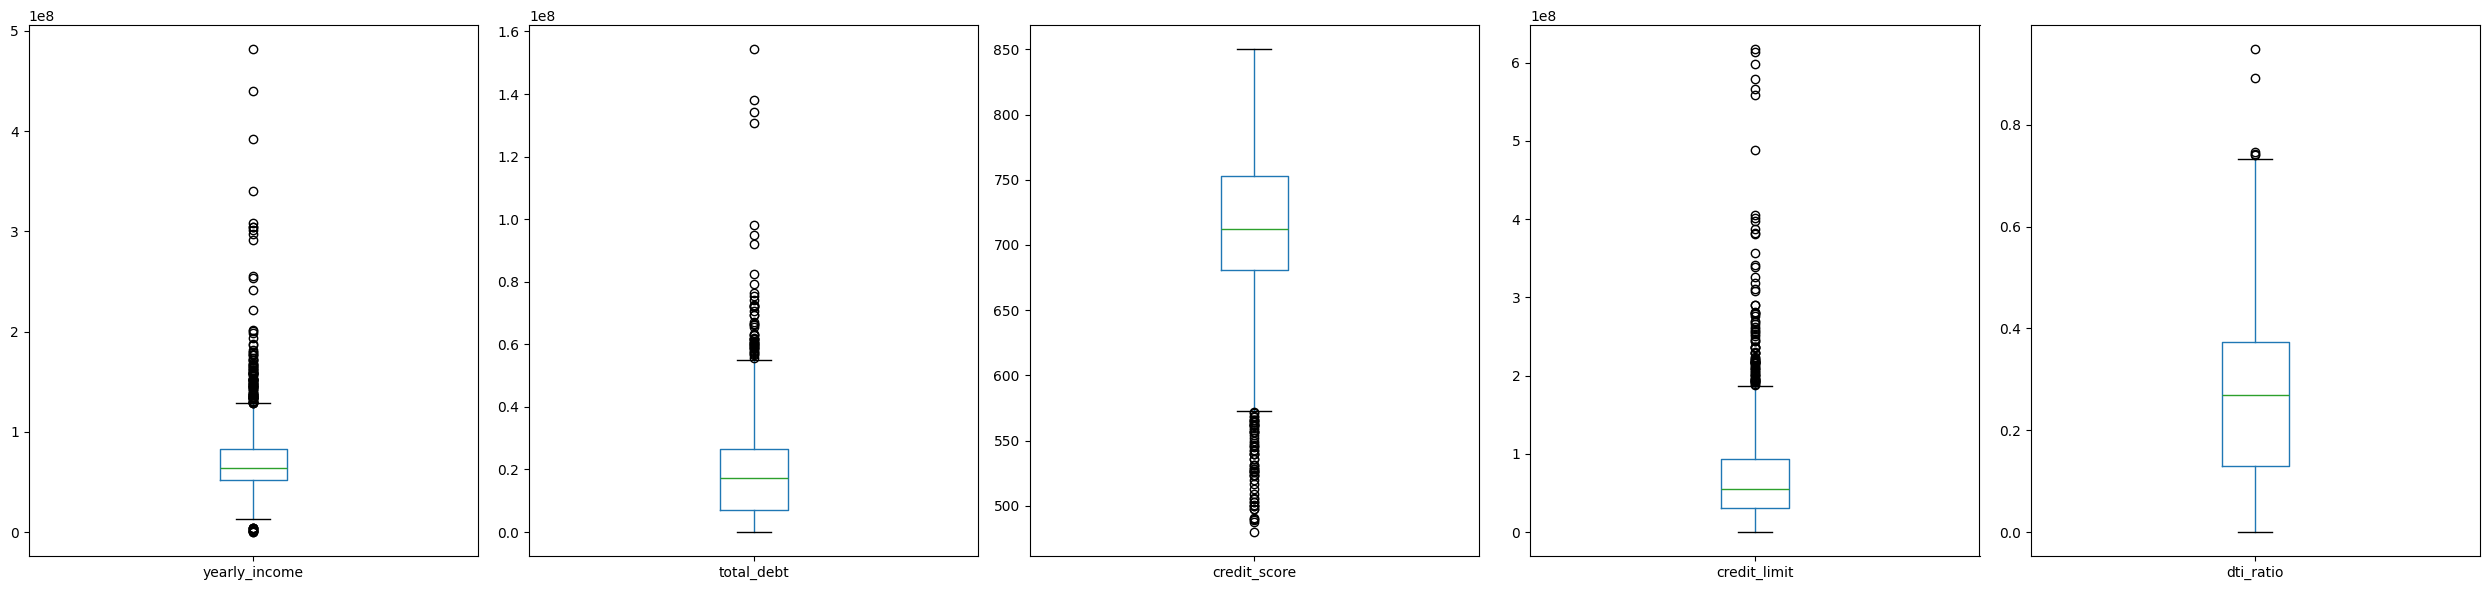

In [ ]:
#Tentukan fitur yang ingin diplot
feature = ['yearly_income', 'total_debt', 'credit_score', 'credit_limit', 'dti_ratio']
#Buat subplot menyesuaikan jumlah fitur
fig, axes = plt.subplots(nrows=1, ncols=len(feature), figsize=(5 * len(feature), 6))

#Looping untuk membuat boxplot
for i, el in enumerate(feature):
    # Jika fitur hanya 1, axes tidak berupa list/array
    ax = axes[i] if len(feature) > 1 else axes
    df_segmentation.boxplot(column=el, ax=ax, grid=False)

plt.tight_layout()
plt.show()

In [ ]:
df_segmentation_feature = df_segmentation[['yearly_income', 'total_debt', 'credit_score', 'credit_limit', 'dti_ratio']]
df_segmentation_feature

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
0,93663000.0,38138095.0,787,164867000.0,0.407184
1,121212000.0,57186095.0,701,102033000.0,0.471786
2,52535000.0,58666.0,698,209210000.0,0.001117
3,392132000.0,60467238.0,722,558975000.0,0.154201
4,172099000.0,54946285.0,675,54758000.0,0.319271
...,...,...,...,...,...
1933,75328000.0,26250666.0,703,95255000.0,0.348485
1934,77474000.0,31224571.0,740,79140000.0,0.403033
1935,48548000.0,21238666.0,779,45524000.0,0.437478
1936,85752000.0,8141142.0,618,14435000.0,0.094938


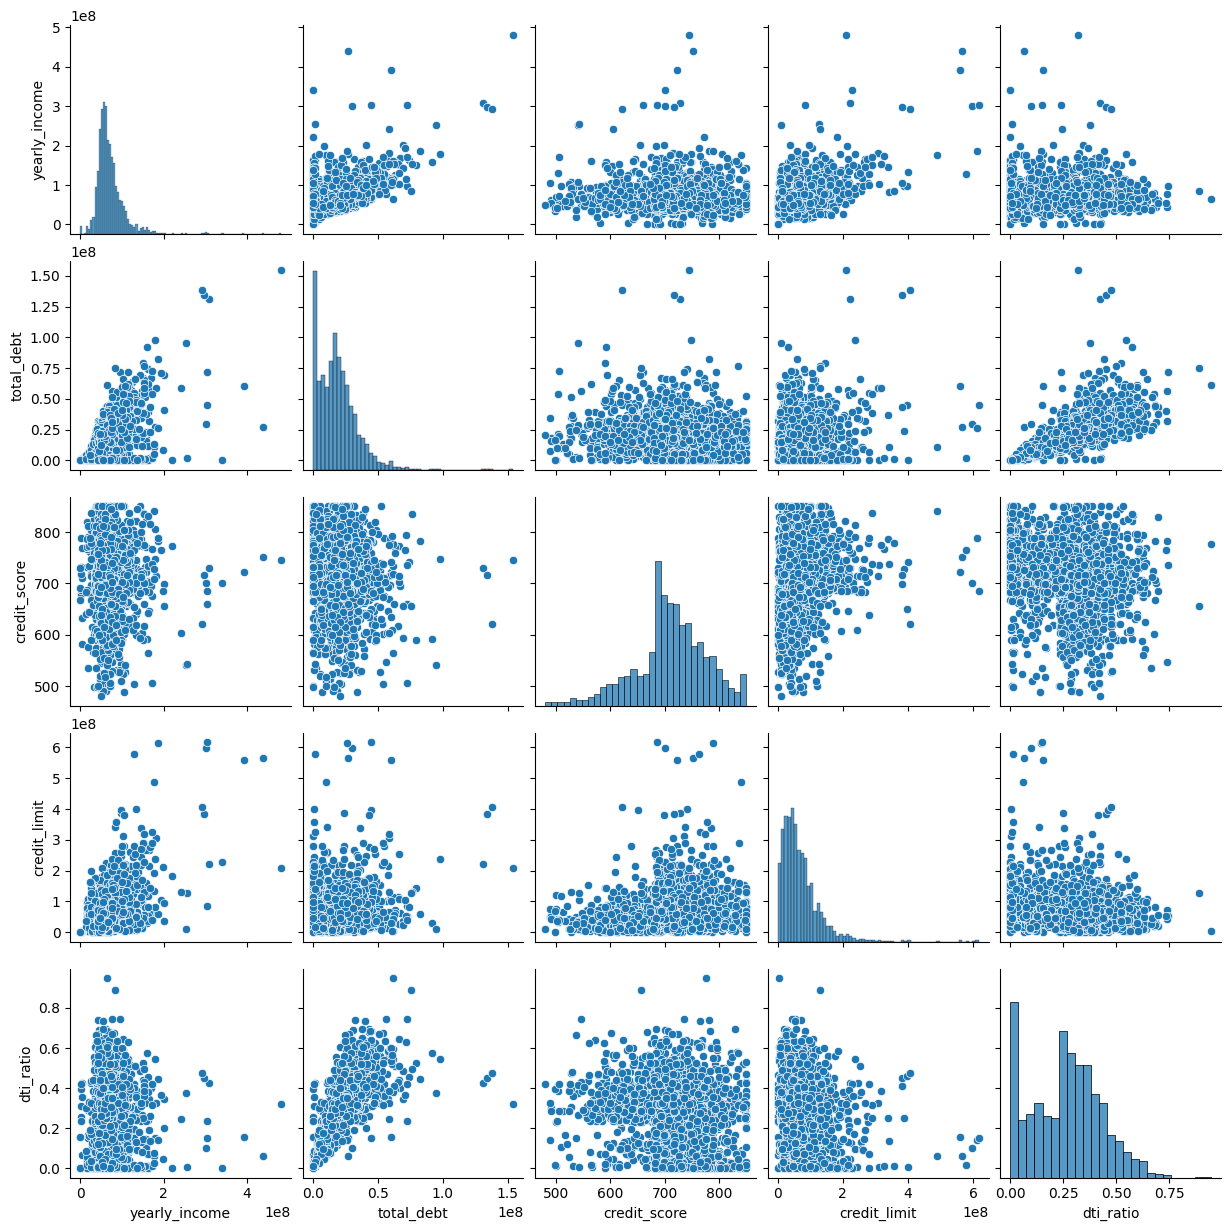

In [ ]:
sns.pairplot(df_segmentation_feature);

## Min-Max Scaler

In [ ]:
# Data original
df_segmentation_feature.head()

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
0,93663000.0,38138095.0,787,164867000.0,0.407184
1,121212000.0,57186095.0,701,102033000.0,0.471786
2,52535000.0,58666.0,698,209210000.0,0.001117
3,392132000.0,60467238.0,722,558975000.0,0.154201
4,172099000.0,54946285.0,675,54758000.0,0.319271


In [ ]:
MinMaxScaler().fit_transform(df_segmentation_feature)

array([[1.94433142e-01, 2.47186169e-01, 8.29729730e-01, 2.66873061e-01,
        4.29374322e-01],
       [2.51623390e-01, 3.70642838e-01, 5.97297297e-01, 1.64972211e-01,
        4.97496420e-01],
       [1.09053618e-01, 3.80234613e-04, 5.89189189e-01, 3.38786187e-01,
        1.17755955e-03],
       ...,
       [1.00776819e-01, 1.37655132e-01, 8.08108108e-01, 7.33289114e-02,
        4.61318667e-01],
       [1.78010330e-01, 5.27655538e-02, 3.72972973e-01, 2.29104196e-02,
        1.00112016e-01],
       [2.14669468e-01, 3.51102508e-01, 5.21621622e-01, 1.07576964e-01,
        5.52391719e-01]])

In [ ]:
# Get the object first and put it in variable if needed
minmax = MinMaxScaler()
# Call the variable and use .fit_transform() function, put our data in the input
minmax_result = minmax.fit_transform(df_segmentation_feature)
minmax_result

array([[1.94433142e-01, 2.47186169e-01, 8.29729730e-01, 2.66873061e-01,
        4.29374322e-01],
       [2.51623390e-01, 3.70642838e-01, 5.97297297e-01, 1.64972211e-01,
        4.97496420e-01],
       [1.09053618e-01, 3.80234613e-04, 5.89189189e-01, 3.38786187e-01,
        1.17755955e-03],
       ...,
       [1.00776819e-01, 1.37655132e-01, 8.08108108e-01, 7.33289114e-02,
        4.61318667e-01],
       [1.78010330e-01, 5.27655538e-02, 3.72972973e-01, 2.29104196e-02,
        1.00112016e-01],
       [2.14669468e-01, 3.51102508e-01, 5.21621622e-01, 1.07576964e-01,
        5.52391719e-01]])

In [ ]:
df_minmax = pd.DataFrame(minmax_result, columns=df_segmentation_feature.columns)
df_minmax

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
0,0.194433,0.247186,0.829730,0.266873,0.429374
1,0.251623,0.370643,0.597297,0.164972,0.497496
2,0.109054,0.000380,0.589189,0.338786,0.001178
3,0.814039,0.391909,0.654054,0.906017,0.162605
4,0.357262,0.356126,0.527027,0.088304,0.336671
...,...,...,...,...,...
1933,0.156371,0.170140,0.602703,0.153980,0.367476
1934,0.160826,0.202377,0.702703,0.127846,0.424997
1935,0.100777,0.137655,0.808108,0.073329,0.461319
1936,0.178010,0.052766,0.372973,0.022910,0.100112


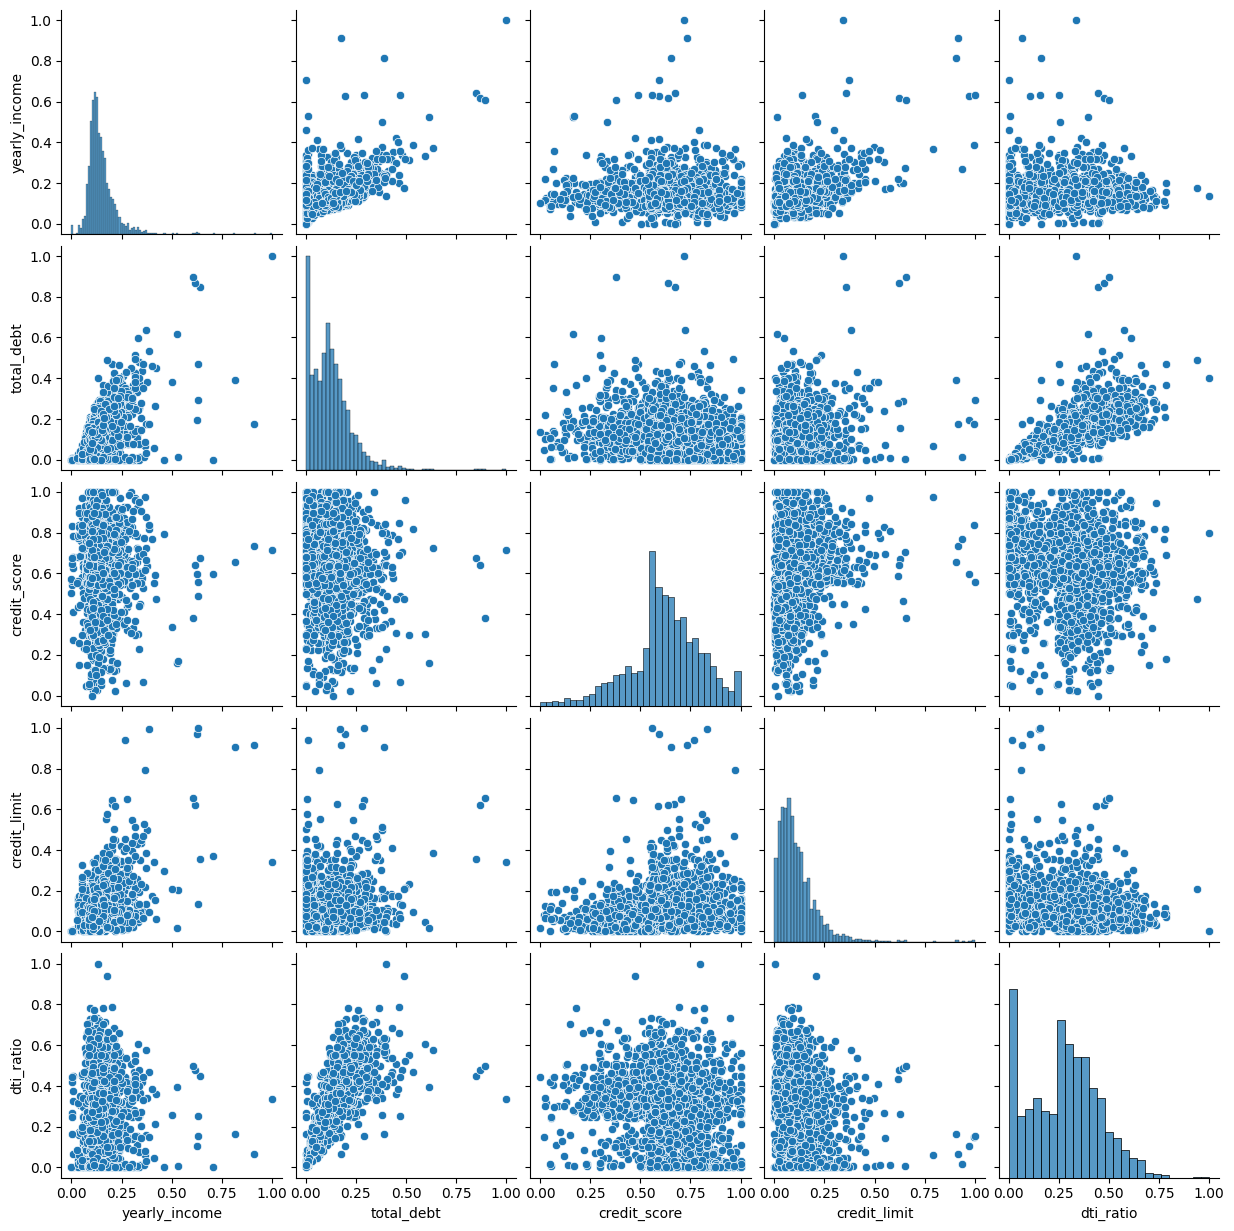

In [ ]:
# Let's see the result in pairplot
sns.pairplot(df_minmax)

In [ ]:
df_minmax.describe()

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
count,1938.000000,1938.000000,1938.000000,1938.000000,1938.000000
mean,0.148602,0.122543,0.622801,0.115098,0.276353
std,0.074366,0.100837,0.180414,0.102756,0.175021
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.106759,0.045923,0.543243,0.049422,0.136814
50%,0.131920,0.112190,0.627027,0.089275,0.283105
75%,0.170940,0.171437,0.737838,0.150961,0.392726
max,1.000000,1.000000,1.000000,1.000000,1.000000


## Standard Scaler

In [ ]:
# Do the same thing for StandardScaler()
std_scaler = StandardScaler()
df_std = pd.DataFrame(std_scaler.fit_transform(df_segmentation_feature), columns=df_segmentation_feature.columns)
df_std

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
0,0.616446,1.236406,1.147259,1.477423,0.874527
1,1.385682,2.461044,-0.141401,0.485493,1.263850
2,-0.531949,-1.211804,-0.186354,2.177444,-1.572653
3,8.950435,2.671996,0.173272,7.699014,-0.650084
4,2.806572,2.317042,-0.530996,-0.260814,0.344717
...,...,...,...,...,...
1933,0.104488,0.472137,-0.111432,0.378492,0.520773
1934,0.164410,0.791921,0.442991,0.124092,0.849509
1935,-0.643276,0.149905,1.027384,-0.406587,1.057091
1936,0.395552,-0.692164,-1.385108,-0.897374,-1.007234


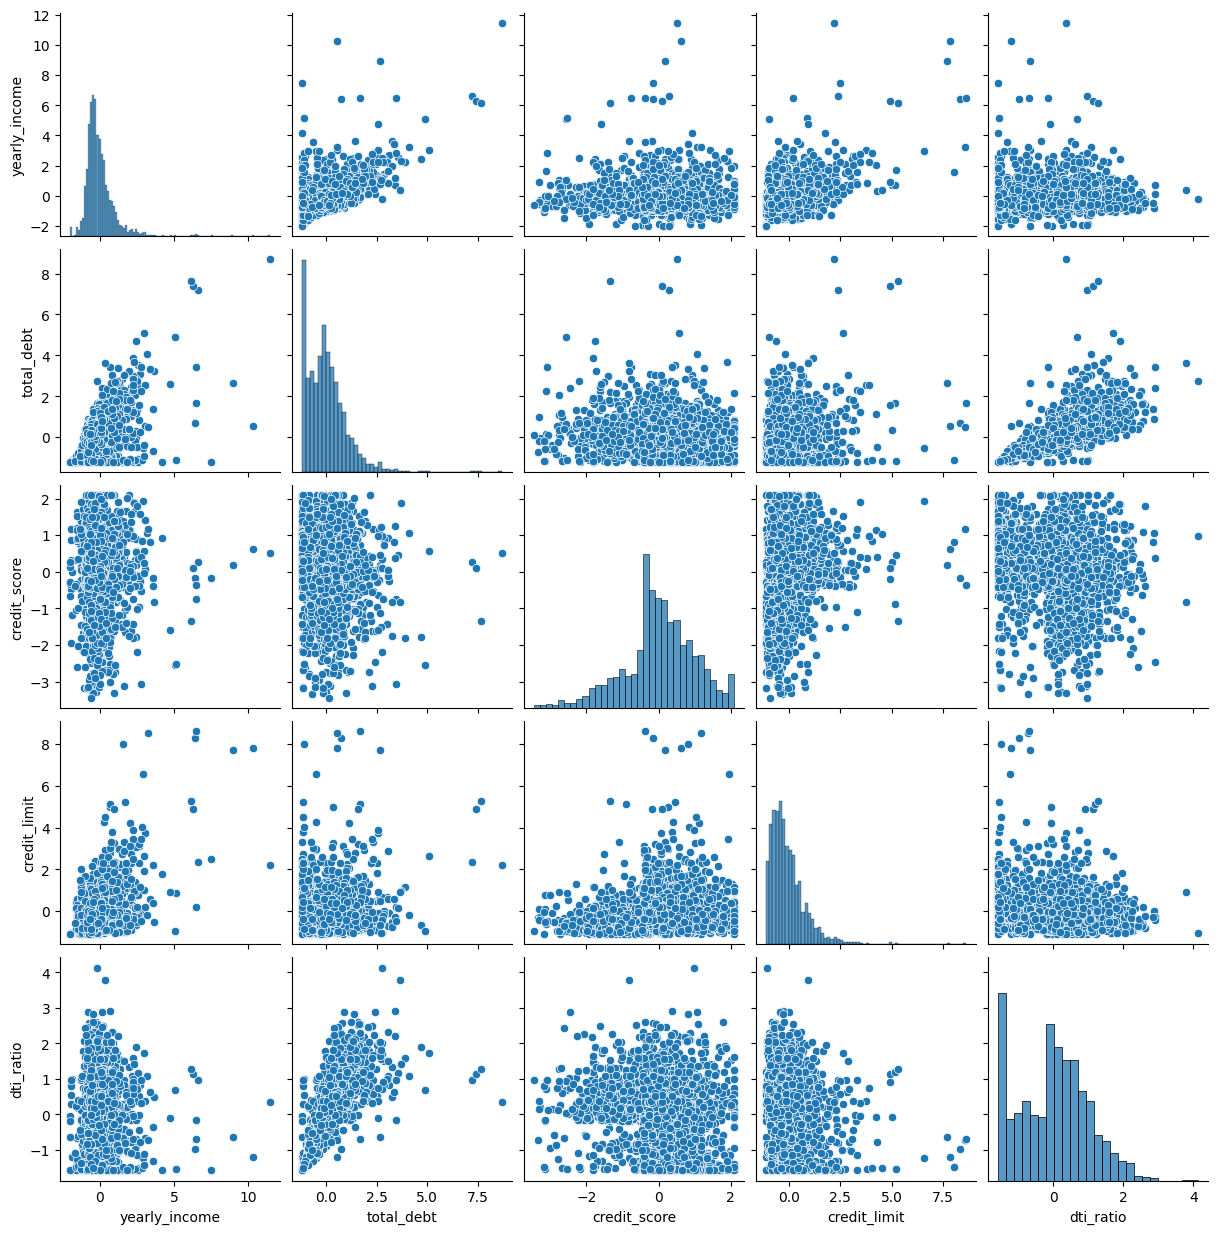

In [ ]:
sns.pairplot(df_std)

In [ ]:
# Set option for float display, to show 4 numbers after decimal
pd.set_option('display.float_format','{:.4f}'.format)

In [ ]:
df_std.describe()

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
count,1938.0000,1938.0000,1938.0000,1938.0000,1938.0000
mean,-0.0000,-0.0000,0.0000,0.0000,-0.0000
std,1.0003,1.0003,1.0003,1.0003,1.0003
min,-1.9988,-1.2156,-3.4530,-1.1204,-1.5794
25%,-0.5628,-0.7600,-0.4411,-0.6393,-0.7975
50%,-0.2244,-0.1027,0.0234,-0.2514,0.0386
75%,0.3004,0.4850,0.6378,0.3491,0.6651
max,11.4517,8.7040,2.0913,8.6139,4.1357


## Robust Scaler

In [ ]:
# Do the same thing for RobustScaler()
robust_scaler = RobustScaler()
df_robust = pd.DataFrame(robust_scaler.fit_transform(df_segmentation_feature), columns=df_segmentation_feature.columns)
df_robust

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
0,0.9740,1.0755,1.0417,1.7491,0.5716
1,1.8651,2.0591,-0.1528,0.7455,0.8378
2,-0.3563,-0.8908,-0.1944,2.4573,-1.1017
3,10.6280,2.2286,0.1389,8.0436,-0.4709
4,3.5110,1.9435,-0.5139,-0.0096,0.2093
...,...,...,...,...,...
1933,0.3810,0.4617,-0.1250,0.6372,0.3297
1934,0.4504,0.7185,0.3889,0.3799,0.5545
1935,-0.4852,0.2029,0.9306,-0.1570,0.6964
1936,0.7181,-0.4734,-1.3056,-0.6536,-0.7151


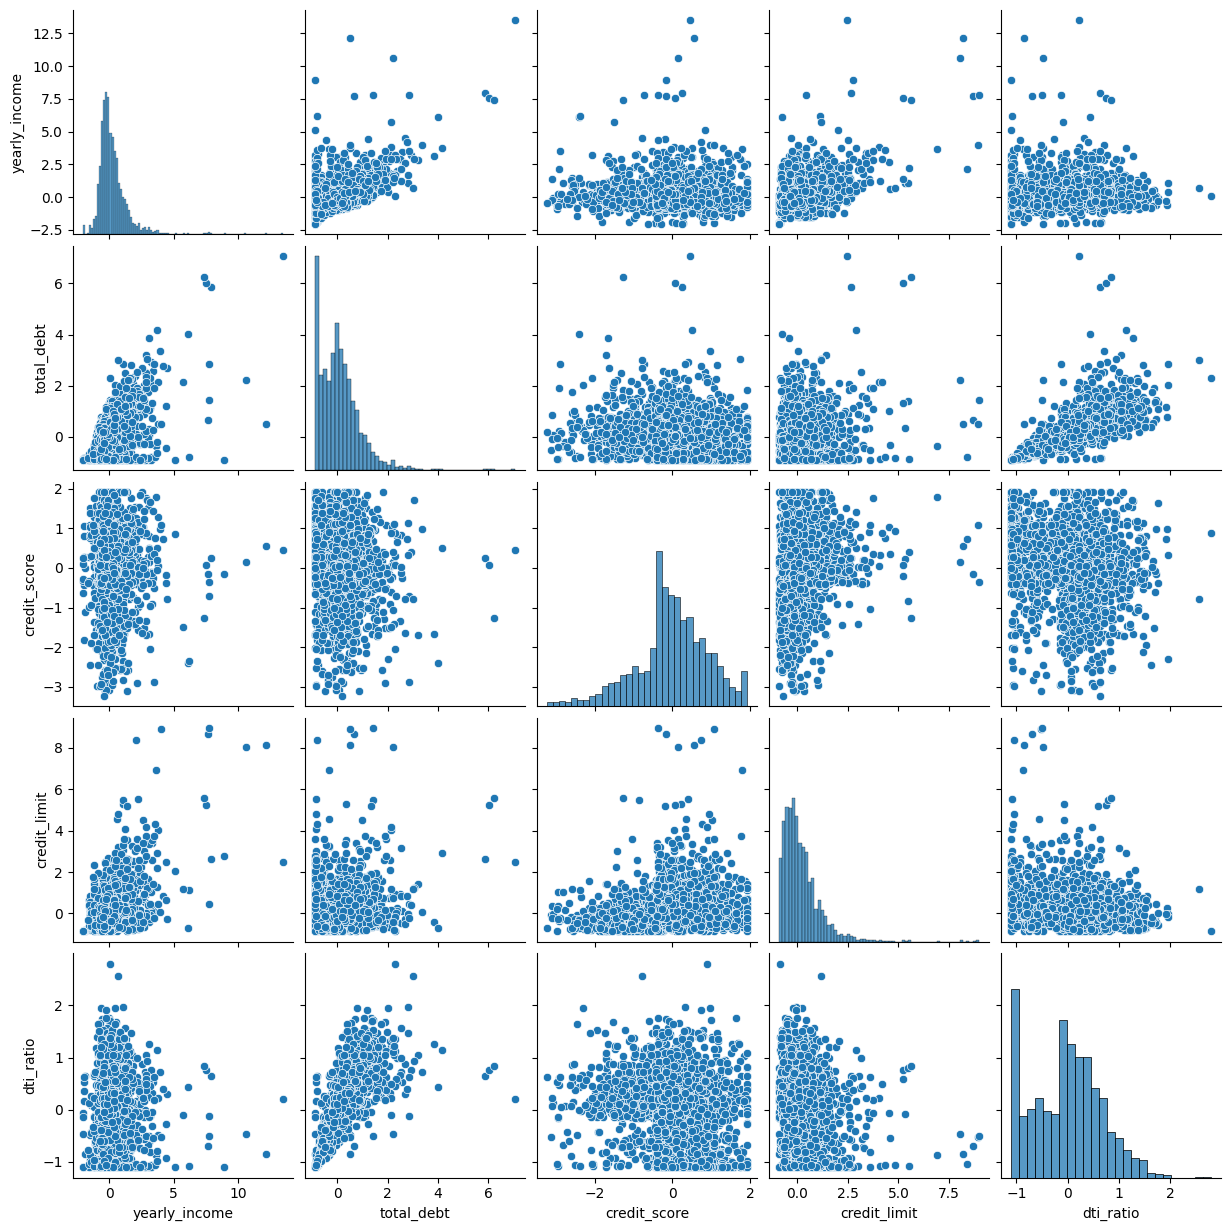

In [ ]:
sns.pairplot(df_robust)

In [ ]:
df_robust.describe()

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
count,1938.0000,1938.0000,1938.0000,1938.0000,1938.0000
mean,0.2599,0.0825,-0.0217,0.2543,-0.0264
std,1.1587,0.8034,0.9271,1.0120,0.6839
min,-2.0554,-0.8938,-3.2222,-0.8792,-1.1063
25%,-0.3920,-0.5280,-0.4306,-0.3925,-0.5716
50%,0.0000,0.0000,0.0000,0.0000,0.0000
75%,0.6080,0.4720,0.5694,0.6075,0.4284
max,13.5255,7.0734,1.9167,8.9692,2.8013


Dari hasil feature scaling, akan digunakan Robust Scaling dengan alasan banyaknya outlier yang terdapat pada kolom yang digunakan, sehingga outlier tidak akan mengganggu hasil dari K-means, maka akan digunakan Robust Scaler

## K-Means Initial Approach

In [ ]:
# Data final yang akan dicluster
df_robust.head()

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
0,0.9740,1.0755,1.0417,1.7491,0.5716
1,1.8651,2.0591,-0.1528,0.7455,0.8378
2,-0.3563,-0.8908,-0.1944,2.4573,-1.1017
3,10.6280,2.2286,0.1389,8.0436,-0.4709
4,3.5110,1.9435,-0.5139,-0.0096,0.2093


### Training the Model

In [ ]:
# Initialize KMeans for 3 clusters and random_state=42 (See Appendix about Random State)
cluster_model = KMeans(n_clusters=3, random_state=42, n_init='auto')
cluster_model

KMeans(n_clusters=3, random_state=42)

In [ ]:
# Call the model variable, and use .fit() function and use "df_robust" as input
cluster_model.fit(df_robust)

KMeans(n_clusters=3, random_state=42)

### Evaluating the Model

In [ ]:
# Untuk melihat Inertia dari model kita, panggil modelnya lalu gunakan ".inertia_"
cluster_model.inertia_

5318.32902374859

### Get the Cluster Label

In [ ]:
# Check up cluster label created by the KMeans, panggil modelnya lalu pakai ".labels_"
cluster_model.labels_

array([2, 2, 1, ..., 1, 0, 0], dtype=int32)

In [ ]:
# Remember our original dataframe is called "df_segmentation_feature", it is not sorted or removed row
df_result = df_segmentation_feature.copy()
df_result['cluster'] = cluster_model.labels_
df_result

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio,cluster
0,93663000.0000,38138095.0000,787,164867000.0000,0.4072,2
1,121212000.0000,57186095.0000,701,102033000.0000,0.4718,2
2,52535000.0000,58666.0000,698,209210000.0000,0.0011,1
3,392132000.0000,60467238.0000,722,558975000.0000,0.1542,2
4,172099000.0000,54946285.0000,675,54758000.0000,0.3193,2
...,...,...,...,...,...,...
1933,75328000.0000,26250666.0000,703,95255000.0000,0.3485,0
1934,77474000.0000,31224571.0000,740,79140000.0000,0.4030,0
1935,48548000.0000,21238666.0000,779,45524000.0000,0.4375,1
1936,85752000.0000,8141142.0000,618,14435000.0000,0.0949,0


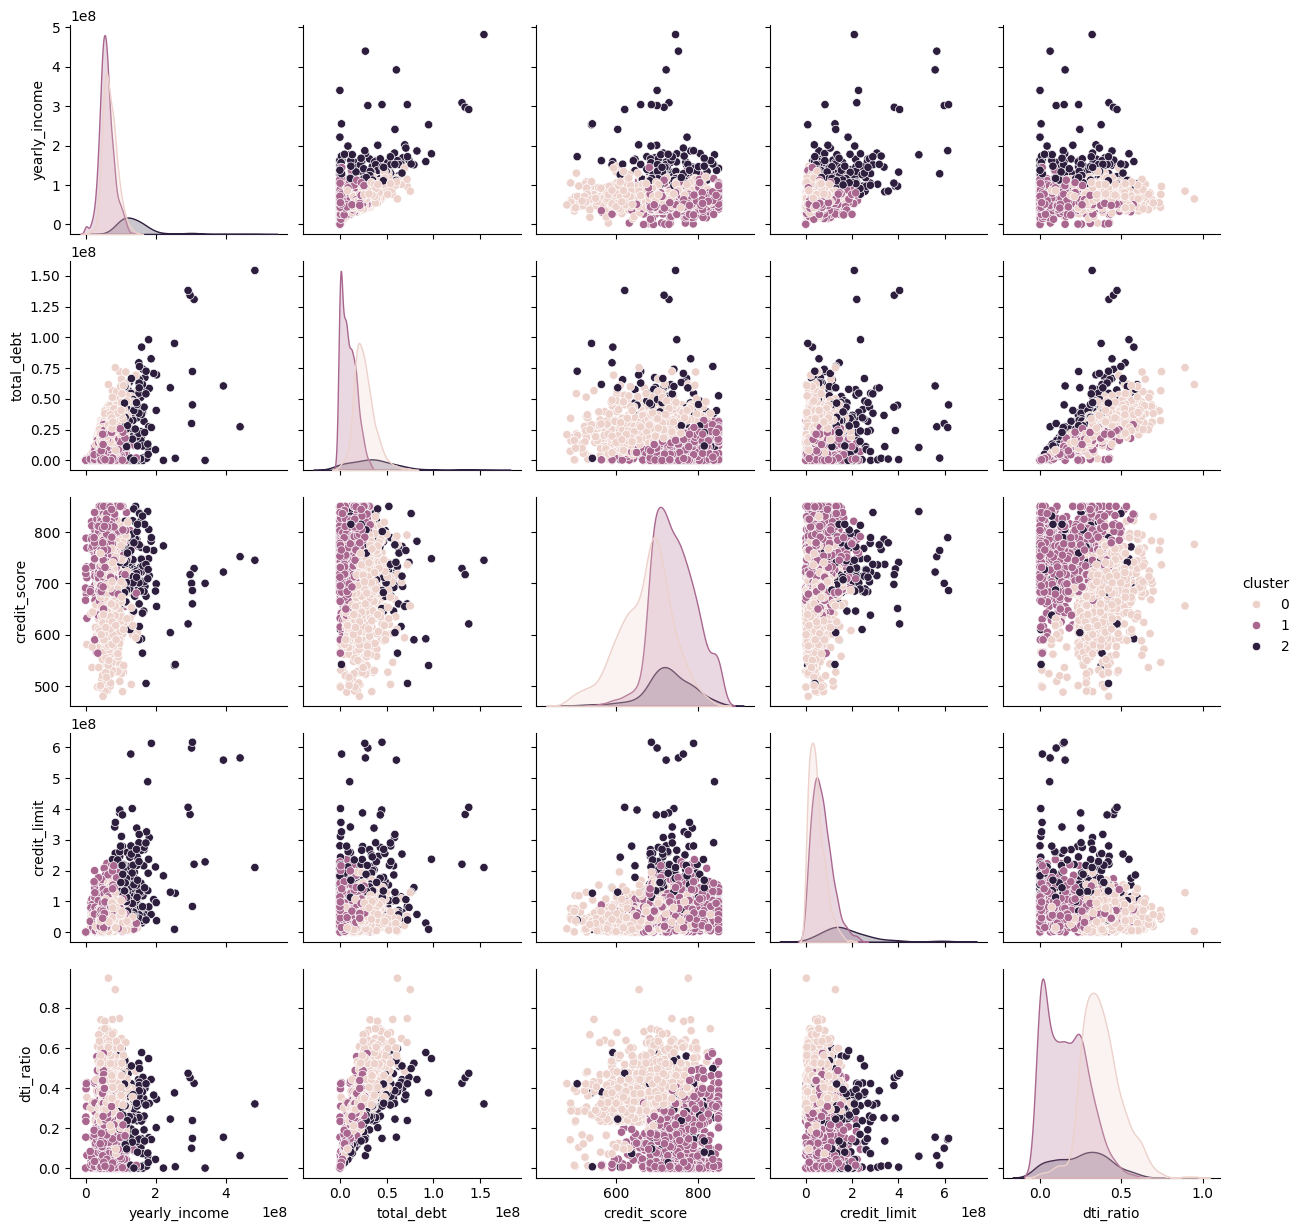

In [ ]:
# Let's re-look into data after clustering
# Karena kita sudah punya kategori di "cluster", kita bisa taruh di "hue" untuk melihat di warna berbeda
sns.pairplot(df_result, hue='cluster')

## Elbow Method

In [ ]:
#We can get the model inertia using ".inertia_"
cluster_model.inertia_

5318.32902374859

In [ ]:
# Create empty list to store the inertia value for each K later
inertia = []

K_range = range(2,11)

for K in K_range:
  # Create the model
  kmeanModel = KMeans(n_clusters=K, random_state=42, n_init='auto')
  # Train them using "df_robust" data (final data scaled by robust scaler)
  kmeanModel.fit(df_robust)
  # Get the inertia value and put it in our empty list "inertia"
  inertia.append(kmeanModel.inertia_)

# Print output
inertia

[6435.4078054424135,
 5318.32902374859,
 4611.885504849369,
 4005.9408653923306,
 3567.4172132758963,
 3358.547681185432,
 3182.7168467526158,
 2895.0225270857386,
 2747.9188377031296]

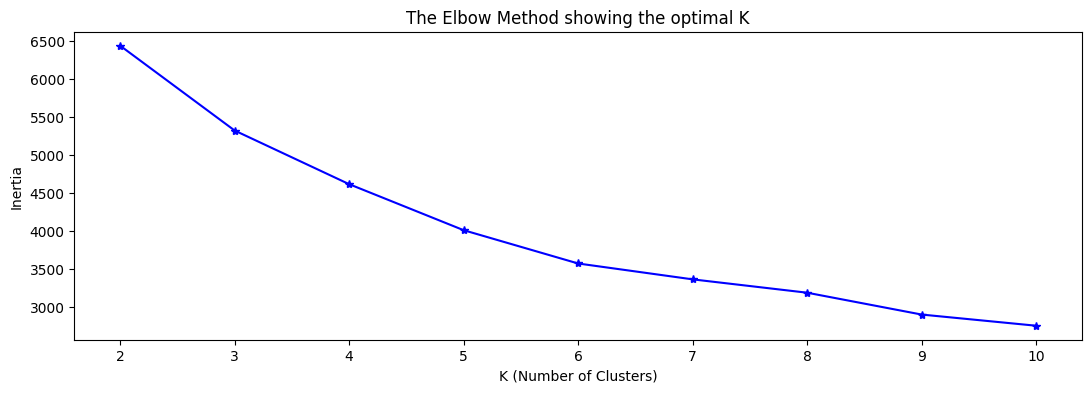

In [ ]:
# Define canvas
plt.figure(figsize=(13,4))

# plot the lineplot using matplotlib
# x-axis -> K_range, y-axis -> inertia
# "b*-" in the third parameter to do styling (b: blue, *: star mark in each point, -: connect by line)
# Ref: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html (bagian marker)
plt.plot(K_range, inertia, 'b*-')

plt.xlabel('K (Number of Clusters)')
plt.ylabel('Inertia')
plt.title('The Elbow Method showing the optimal K');

## Silhouette Method

In [ ]:
!pip install yellowbrick

In [ ]:
from yellowbrick.cluster import SilhouetteVisualizer

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


Silhouette Score: 0.2156123123094488


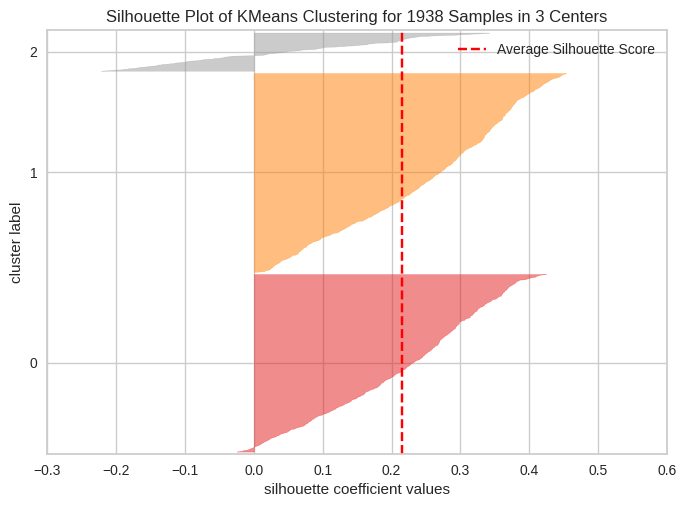

In [ ]:
cluster_model = KMeans(n_clusters=3, random_state=42, n_init='auto')
cluster_model.fit(df_robust)

# Since our model is already fitted, we use "is_fitted=True"
sil = SilhouetteVisualizer(cluster_model, is_fitted=True)

# "Fit" here is to generate the silhouette visualization
sil.fit(df_robust)

# Give labels and titles for the visualization
sil.finalize()

# In "sil" variable we created, we can use ".silhouette_score_" to get the AVG silhouette score of all data
print("Silhouette Score:", sil.silhouette_score_)

For k=2, the average silhouette score is 0.3684649779774554
For k=3, the average silhouette score is 0.2156123123094488
For k=4, the average silhouette score is 0.218842308458633
For k=5, the average silhouette score is 0.21790702849351704
For k=6, the average silhouette score is 0.22191947424613515
For k=7, the average silhouette score is 0.18370086442076838
For k=8, the average silhouette score is 0.17614493518086577
For k=9, the average silhouette score is 0.18581076365706156
For k=10, the average silhouette score is 0.18404970328404166


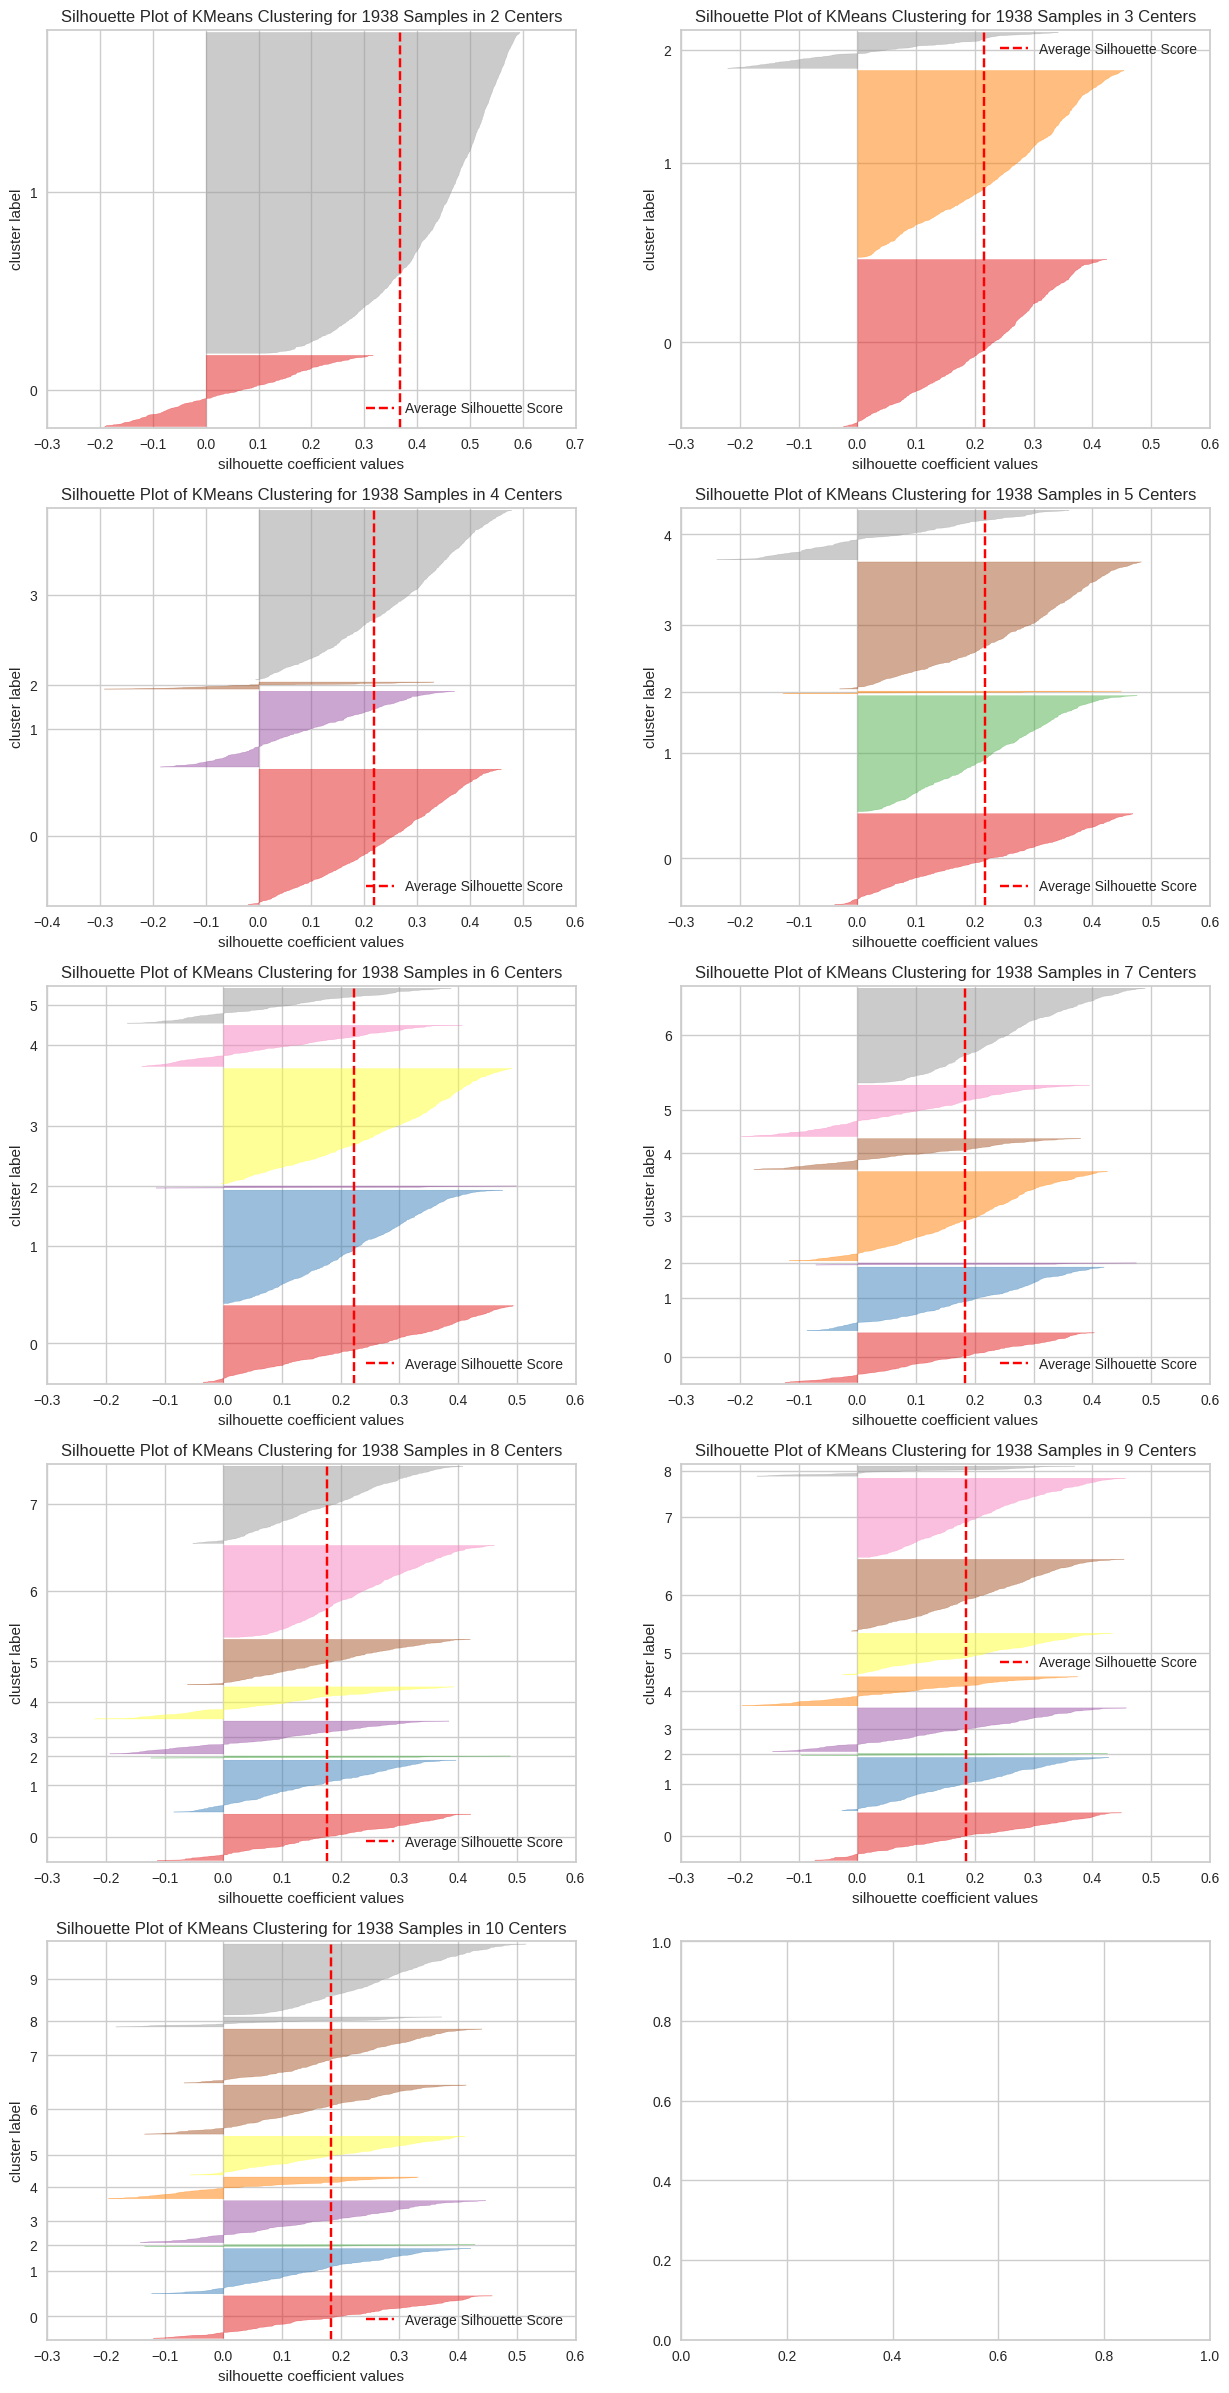

In [ ]:
# Lakukan hal yang sama untuk setiap K_range 2-10
K_range = range(2,11)

# Hitung banyak K yang akan diplot
banyak_K = len(K_range)
# Dibagi 2 dan dibulatkan ke atas pakai np.ceil() -- (jangan lupa ubah ke int)
n_baris = int(np.ceil(banyak_K/2))

# Define canvasnya
fig, ax = plt.subplots(n_baris, 2, figsize=(15,30))


for index, K in enumerate(K_range):
  kmeanModel = KMeans(n_clusters=K, random_state=42, n_init='auto')

  sil = SilhouetteVisualizer(kmeanModel, is_fitted=False, ax=ax.flatten()[index])
  sil.fit(df_robust)
  sil.finalize()
  print(f"For k={K}, the average silhouette score is {sil.silhouette_score_}")

Dari hasil Elbow method dan Silhouette method, diputuskan untuk menggunakan K = 3. Alasannya kerena K = 3 memiliki Silhouette Score yang relatif stabil jika dibandingkan dengan k = 4 dan seterusnya, dan juga distribusi K=3 masih sangat proporsional dan ada sedikit data yang negatif tetapi masih bisa diterima.

## Rerun Cluster Using K = 3

In [ ]:
cluster_model = KMeans(n_clusters=3, random_state=42, n_init='auto')
cluster_model.fit(df_robust)

KMeans(n_clusters=3, random_state=42)

In [ ]:
# Copy the original dataframe to "df_result" and put the cluster label there
df_result = df_segmentation_feature.copy()
df_result['cluster'] = cluster_model.labels_
df_result

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio,cluster
0,93663000.0000,38138095.0000,787,164867000.0000,0.4072,2
1,121212000.0000,57186095.0000,701,102033000.0000,0.4718,2
2,52535000.0000,58666.0000,698,209210000.0000,0.0011,1
3,392132000.0000,60467238.0000,722,558975000.0000,0.1542,2
4,172099000.0000,54946285.0000,675,54758000.0000,0.3193,2
...,...,...,...,...,...,...
1933,75328000.0000,26250666.0000,703,95255000.0000,0.3485,0
1934,77474000.0000,31224571.0000,740,79140000.0000,0.4030,0
1935,48548000.0000,21238666.0000,779,45524000.0000,0.4375,1
1936,85752000.0000,8141142.0000,618,14435000.0000,0.0949,0


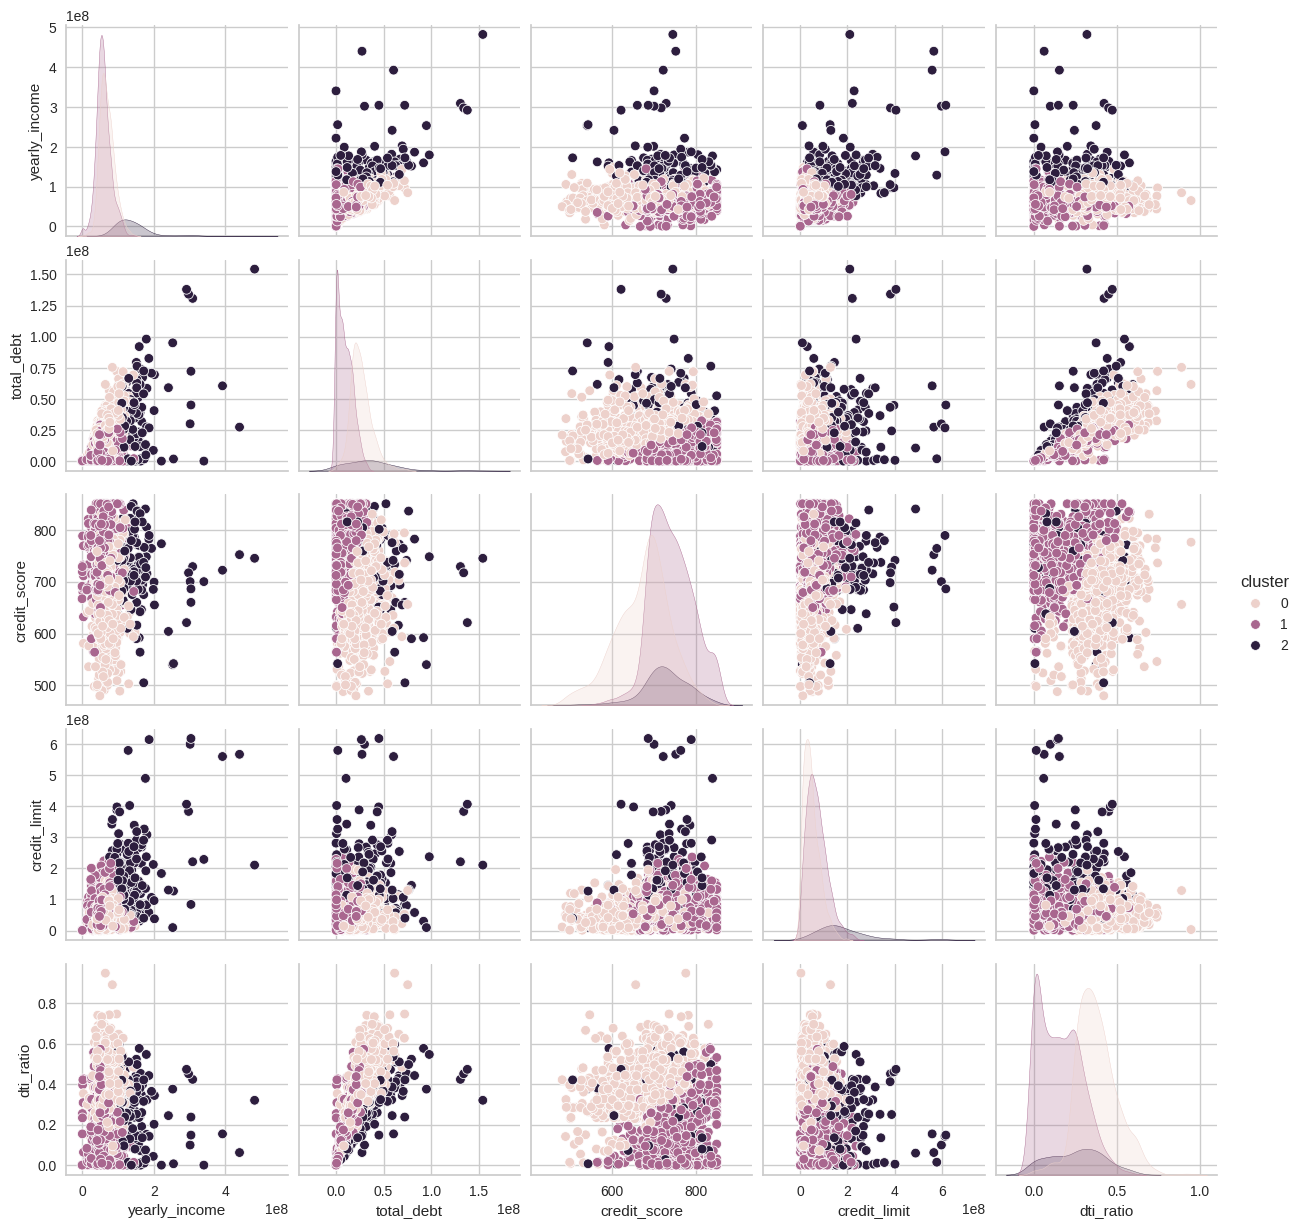

In [ ]:
# Let's see the clusters created
sns.pairplot(df_result, hue='cluster')

## Agg for profiling

In [ ]:
# Jalankan ulang/fit model KMeans dengan K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init="auto")
kmeans.fit(df_robust)

KMeans(n_clusters=3, random_state=42)

In [ ]:
#Tambahkan kolom 'cluster' ke df_merged
df_merged["cluster"] = kmeans.labels_

In [ ]:
#Agregasi profil
cluster_profile_median = df_merged.groupby("cluster")[
    [
        "yearly_income",
        "total_debt",
        "credit_score",
        "credit_limit",
        "dti_ratio",
    ]
].median()

display(cluster_profile_median)

,yearly_income,total_debt,credit_score,credit_limit,dti_ratio
cluster,,,,,
0,66315999.5000,24450666.0000,683.0000,40783000.0000,0.3621
1,57537000.0000,7760190.0000,736.0000,63940000.0000,0.1475
2,129126000.0000,33928952.0000,727.0000,154584000.0000,0.2652


Insight:
* 0=Middle Income and High Debt / high Rist: Nasabah dengan beban utang relatif tinggi terhadap pendapatannya, risiko kredit lebih tinggi dibanding kelompok lain ==> Batasi kenaikan limit kredit untuk mencegah default / gagal bayar, tawarkan program konsolidasi utang atau cicilan dengan bunga khusus agar mereka bisa mengelola utangnya lebih baik
* 1=Low Income, Low Debt and High Credit Score: Nasabah konservatif yang sangat menjaga kesehatan finansialnya, berisiko rendah (low risk), tetapi batas limit kreditnya masih moderat ==> Tawarkan program penawaran kenaikan limit kredit (credit limit increase) karena riwayat kredit dan DTI mereka sangat baik, Berikan cashback atau promo transaksi rutin untuk mendorong penggunaan kartu
* 2=High-Net_Worth/Priority Customers: Nasabah Sultan / Kelas Atas dengan kapasitas finansial dan daya beli yang sangat tinggi ==> Tawarkan produk kartu kredit premium/black card, layanan VIP lounge, atau poin reward gaya hidup (travel & dining), Tawarkan produk investasi, asuransi, atau wealth management.